In [1]:
{
 "cells": [],
 "metadata": {},
 "nbformat": 4,
 "nbformat_minor": 5
}

{'cells': [], 'metadata': {}, 'nbformat': 4, 'nbformat_minor': 5}

In [2]:

import numpy as np
import pandas as pd
from pathlib import Path

# Reproduce the baseline parameters from our matrix analysis
Nv = 32
k = 0.5
dt = 0.001

v = np.linspace(-6.0, 6.0, Nv)
dv = (v[-1] - v[0]) / (Nv - 1)

# Trapezoidal quadrature weights
w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

# Maxwellian equilibrium and its velocity derivative
f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
f0_prime = -v * f0

# Construct M_k and A_k
V = np.diag(v)
M_k = (
    -1j * k * V
    + (1 / (1j * k)) * np.outer(f0_prime, w)
)

I = np.eye(Nv, dtype=complex)
D_k = 1j * dt * k * V
R_k = -(dt / (1j * k)) * np.outer(f0_prime, w)

A_k = I - dt * M_k
A_decomposed = I + D_k + R_k

# Check whether the decomposition is correct
reconstruction_error = np.linalg.norm(
    A_k - A_decomposed, ord=2
)

# Operator 2-norms
norm_I = np.linalg.norm(I, ord=2)
norm_D = np.linalg.norm(D_k, ord=2)
norm_R = np.linalg.norm(R_k, ord=2)
norm_A = np.linalg.norm(A_k, ord=2)

# Naive linear-combination-of-unitaries (LCU)
# normalization upper bound
alpha_lcu = norm_I + norm_D + norm_R

print("MATRIX DECOMPOSITION")
print("--------------------")
print(f"||A - (I + D + R)||_2 = {reconstruction_error:.3e}")
print(f"||I||_2               = {norm_I:.8f}")
print(f"||D||_2               = {norm_D:.8f}")
print(f"||R||_2               = {norm_R:.8f}")
print(f"||A||_2               = {norm_A:.8f}")
print(f"LCU normalization α   = {alpha_lcu:.8f}")
print(f"α / ||A||_2            = {alpha_lcu / norm_A:.8f}")

# Save the results
table_dir = Path("../results/tables/matrix_analysis")
table_dir.mkdir(parents=True, exist_ok=True)

summary = pd.DataFrame([{
    "Nv": Nv,
    "k": k,
    "dt": dt,
    "norm_I": norm_I,
    "norm_D": norm_D,
    "norm_R": norm_R,
    "norm_A": norm_A,
    "alpha_lcu": alpha_lcu,
    "alpha_over_norm_A": alpha_lcu / norm_A,
    "reconstruction_error": reconstruction_error,
}])

summary.to_csv(
    table_dir / "block_encoding_decomposition.csv",
    index=False
)

print("\nSaved block_encoding_decomposition.csv")


MATRIX DECOMPOSITION
--------------------
||A - (I + D + R)||_2 = 4.337e-19
||I||_2               = 1.00000000
||D||_2               = 0.00300000
||R||_2               = 0.00258091
||A||_2               = 1.00129161
LCU normalization α   = 1.00558091
α / ||A||_2            = 1.00428377

Saved block_encoding_decomposition.csv


In [3]:

# Analyze the rank-one correction and its vector factors

u = f0_prime.astype(complex)
z = w.astype(complex)

# R_k = coefficient * u z^T
coefficient = -(dt / (1j * k))

# Confirm rank and reconstruction
rank_R = np.linalg.matrix_rank(R_k)
R_reconstructed = coefficient * np.outer(u, z)

rank_reconstruction_error = np.linalg.norm(
    R_k - R_reconstructed, ord=2
)

# Singular values of the rank-one correction
singular_values_R = np.linalg.svd(
    R_k, compute_uv=False
)

# Norm identity for an outer product:
# ||u z^T||_2 = ||u||_2 ||z||_2
norm_R_direct = np.linalg.norm(R_k, ord=2)
norm_R_factorized = (
    abs(coefficient)
    * np.linalg.norm(u)
    * np.linalg.norm(z)
)

print("RANK-ONE STRUCTURE")
print("------------------")
print(f"Numerical rank of R_k       : {rank_R}")
print(f"||f0_prime||_2              : {np.linalg.norm(u):.8f}")
print(f"||w||_2                     : {np.linalg.norm(z):.8f}")
print(f"|coefficient|               : {abs(coefficient):.8e}")
print(f"||R_k||_2, direct            : {norm_R_direct:.8f}")
print(f"||R_k||_2, factorized        : {norm_R_factorized:.8f}")
print(f"Reconstruction error         : {rank_reconstruction_error:.3e}")
print(
    "Largest singular value      : "
    f"{singular_values_R[0]:.8f}"
)
print(
    "Second singular value       : "
    f"{singular_values_R[1]:.3e}"
)

# Save diagnostics
rank_one_table = pd.DataFrame([{
    "Nv": Nv,
    "k": k,
    "dt": dt,
    "rank_R": rank_R,
    "norm_f0_prime": np.linalg.norm(u),
    "norm_w": np.linalg.norm(z),
    "coefficient_magnitude": abs(coefficient),
    "norm_R_direct": norm_R_direct,
    "norm_R_factorized": norm_R_factorized,
    "reconstruction_error": rank_reconstruction_error,
}])

rank_one_table.to_csv(
    table_dir / "rank_one_encoding_analysis.csv",
    index=False
)

print("\nSaved rank_one_encoding_analysis.csv")


RANK-ONE STRUCTURE
------------------
Numerical rank of R_k       : 1
||f0_prime||_2              : 0.60363270
||w||_2                     : 2.13781181
|coefficient|               : 2.00000000e-03
||R_k||_2, direct            : 0.00258091
||R_k||_2, factorized        : 0.00258091
Reconstruction error         : 0.000e+00
Largest singular value      : 0.00258091
Second singular value       : 6.654e-20

Saved rank_one_encoding_analysis.csv


In [4]:

# Test the normalized rank-one operator

norm_R = np.linalg.norm(R_k, ord=2)
B_R = R_k / norm_R

# A rank-one matrix with unit operator norm
singular_values_BR = np.linalg.svd(
    B_R, compute_uv=False
)

# Test its action on a normalized random complex vector
rng = np.random.default_rng(42)
x_test = (
    rng.normal(size=Nv)
    + 1j * rng.normal(size=Nv)
)
x_test /= np.linalg.norm(x_test)

y_test = B_R @ x_test

# Reconstruct B_R from its singular-value decomposition
U_svd, s_svd, Vh_svd = np.linalg.svd(
    B_R, full_matrices=False
)
B_R_rank1 = (
    s_svd[0]
    * np.outer(U_svd[:, 0], Vh_svd[0, :])
)

print("NORMALIZED RANK-ONE OPERATOR")
print("----------------------------")
print(f"||B_R||_2                 : {np.linalg.norm(B_R, 2):.12f}")
print(f"Rank(B_R)                : {np.linalg.matrix_rank(B_R)}")
print(f"Largest singular value   : {singular_values_BR[0]:.12f}")
print(f"Second singular value    : {singular_values_BR[1]:.3e}")
print(f"||B_R x||_2              : {np.linalg.norm(y_test):.8f}")
print(f"Reconstruction error     : {np.linalg.norm(B_R - B_R_rank1, 2):.3e}")

# Save singular values for future analysis
pd.DataFrame({
    "singular_value_index": np.arange(1, len(singular_values_BR) + 1),
    "singular_value": singular_values_BR,
}).to_csv(
    table_dir / "normalized_rank_one_singular_values.csv",
    index=False
)

print("\nSaved normalized_rank_one_singular_values.csv")


NORMALIZED RANK-ONE OPERATOR
----------------------------
||B_R||_2                 : 1.000000000000
Rank(B_R)                : 1
Largest singular value   : 1.000000000000
Second singular value    : 2.299e-17
||B_R x||_2              : 0.06644533
Reconstruction error     : 2.679e-16

Saved normalized_rank_one_singular_values.csv


In [5]:

# Matrix-level LCU block encoding of A_k = I + D_k + R_k

def psd_sqrt(X):
    """Stable square root of a Hermitian positive-semidefinite matrix."""
    Xh = (X + X.conj().T) / 2
    eigenvalues, eigenvectors = np.linalg.eigh(Xh)

    if eigenvalues.min() < -1e-9:
        raise ValueError("Matrix is not positive semidefinite.")

    eigenvalues = np.clip(eigenvalues, 0.0, None)
    return (
        eigenvectors
        @ np.diag(np.sqrt(eigenvalues))
        @ eigenvectors.conj().T
    )


def unitary_dilation(B):
    """Construct a unitary whose upper-left block is contraction B."""
    n = B.shape[0]
    identity = np.eye(n, dtype=complex)

    if np.linalg.norm(B, 2) > 1 + 1e-10:
        raise ValueError("B must be a contraction.")

    top_right = psd_sqrt(identity - B @ B.conj().T)
    bottom_left = psd_sqrt(identity - B.conj().T @ B)

    return np.block([
        [B, top_right],
        [bottom_left, -B.conj().T]
    ])


# 1. Normalize each term
beta_I = np.linalg.norm(I, 2)
beta_D = np.linalg.norm(D_k, 2)
beta_R = np.linalg.norm(R_k, 2)

B_I = I / beta_I
B_D = D_k / beta_D
B_R = R_k / beta_R

alpha = beta_I + beta_D + beta_R
weights = np.array([beta_I, beta_D, beta_R]) / alpha

# 2. Construct unitary dilations
U_I = np.eye(2 * Nv, dtype=complex)
U_D = unitary_dilation(B_D)
U_R = unitary_dilation(B_R)

# A fourth selector branch is unused and receives zero weight.
U_unused = np.eye(2 * Nv, dtype=complex)

# 3. SELECT applies the chosen unitary according to selector state
SELECT = np.zeros((8 * Nv, 8 * Nv), dtype=complex)

branches = [U_I, U_D, U_R, U_unused]
for j, Uj in enumerate(branches):
    start = j * 2 * Nv
    stop = (j + 1) * 2 * Nv
    SELECT[start:stop, start:stop] = Uj

# 4. PREPARE creates sqrt(weight) amplitudes in selector register
p = np.zeros(4)
p[:3] = np.sqrt(weights)
e0 = np.zeros(4)
e0[0] = 1.0

# Householder unitary mapping |0> to p
difference = e0 - p
if np.linalg.norm(difference) > 1e-14:
    q = difference / np.linalg.norm(difference)
    PREPARE = np.eye(4) - 2 * np.outer(q, q)
else:
    PREPARE = np.eye(4)

PREPARE_full = np.kron(PREPARE, np.eye(2 * Nv))

# 5. Combine the branches
U_LCU = (
    PREPARE_full.conj().T
    @ SELECT
    @ PREPARE_full
)

# Project onto selector |0> and dilation ancilla |0>
A_encoded = U_LCU[:Nv, :Nv]
target = A_k / alpha

# 6. Validate
unitarity_error = np.linalg.norm(
    U_LCU.conj().T @ U_LCU - np.eye(8 * Nv), 2
)

block_error = np.linalg.norm(A_encoded - target, 2)

print("COMBINED LCU BLOCK-ENCODING CHECK")
print("--------------------------------")
print(f"Nv                         : {Nv}")
print(f"Full unitary dimension     : {U_LCU.shape[0]}")
print(f"Normalization alpha        : {alpha:.10f}")
print(f"||A_k||_2                  : {np.linalg.norm(A_k, 2):.10f}")
print(f"||U†U - I||_2              : {unitarity_error:.3e}")
print(f"||encoded block - A/alpha||: {block_error:.3e}")

# Save verification results
pd.DataFrame([{
    "Nv": Nv,
    "k": k,
    "dt": dt,
    "alpha_lcu": alpha,
    "norm_A": np.linalg.norm(A_k, 2),
    "unitarity_error": unitarity_error,
    "block_encoding_error": block_error,
}]).to_csv(
    table_dir / "lcu_block_encoding_verification.csv",
    index=False
)

print("\nSaved lcu_block_encoding_verification.csv")


COMBINED LCU BLOCK-ENCODING CHECK
--------------------------------
Nv                         : 32
Full unitary dimension     : 256
Normalization alpha        : 1.0055809062
||A_k||_2                  : 1.0012916075
||U†U - I||_2              : 2.356e-08
||encoded block - A/alpha||: 4.268e-17

Saved lcu_block_encoding_verification.csv


In [6]:

# Diagnose numerical unitarity errors

def unitarity_residual(U):
    identity = np.eye(U.shape[0], dtype=complex)
    return np.linalg.norm(U.conj().T @ U - identity, 2)

print("UNITARITY DIAGNOSTICS")
print("---------------------")
print(f"Identity branch : {unitarity_residual(U_I):.3e}")
print(f"Diagonal branch : {unitarity_residual(U_D):.3e}")
print(f"Rank-one branch : {unitarity_residual(U_R):.3e}")
print(f"SELECT          : {unitarity_residual(SELECT):.3e}")
print(f"PREPARE         : {unitarity_residual(PREPARE):.3e}")
print(f"Combined LCU    : {unitarity_residual(U_LCU):.3e}")

# Verify the PREPARE state and selector weights
prepared_state = PREPARE @ e0

print("\nPREPARE STATE")
print("-------------")
print("Target amplitudes :", np.round(p, 10))
print("Actual amplitudes :", np.round(prepared_state, 10))
print(
    "State error       :",
    f"{np.linalg.norm(prepared_state - p):.3e}"
)


UNITARITY DIAGNOSTICS
---------------------
Identity branch : 0.000e+00
Diagonal branch : 1.110e-16
Rank-one branch : 2.356e-08
SELECT          : 2.356e-08
PREPARE         : 9.877e-16
Combined LCU    : 2.356e-08

PREPARE STATE
-------------
Target amplitudes : [0.99722117 0.05462005 0.05066145 0.        ]
Actual amplitudes : [0.99722117 0.05462005 0.05066145 0.        ]
State error       : 5.009e-16


In [7]:

def psd_sqrt(X, tol=1e-14):
    """Hermitian PSD square root with small roundoff eigenvalues removed."""
    Xh = (X + X.conj().T) / 2
    eigenvalues, eigenvectors = np.linalg.eigh(Xh)

    if eigenvalues.min() < -1e-9:
        raise ValueError(
            f"Matrix is not PSD: min eigenvalue = {eigenvalues.min():.3e}"
        )

    # Remove tiny eigenvalues caused by floating-point roundoff.
    eigenvalues = np.where(eigenvalues < tol, 0.0, eigenvalues)
    eigenvalues = np.maximum(eigenvalues, 0.0)

    return (
        eigenvectors
        @ np.diag(np.sqrt(eigenvalues))
        @ eigenvectors.conj().T
    )


# Rebuild the dilation branches using the revised square root
U_D = unitary_dilation(B_D)
U_R = unitary_dilation(B_R)

branches = [U_I, U_D, U_R, U_unused]
SELECT = np.zeros((8 * Nv, 8 * Nv), dtype=complex)

for j, Uj in enumerate(branches):
    start = j * 2 * Nv
    stop = (j + 1) * 2 * Nv
    SELECT[start:stop, start:stop] = Uj

U_LCU = PREPARE_full.conj().T @ SELECT @ PREPARE_full

print("UPDATED UNITARITY DIAGNOSTICS")
print("-----------------------------")
print(f"Diagonal branch : {unitarity_residual(U_D):.3e}")
print(f"Rank-one branch : {unitarity_residual(U_R):.3e}")
print(f"SELECT          : {unitarity_residual(SELECT):.3e}")
print(f"Combined LCU    : {unitarity_residual(U_LCU):.3e}")

A_encoded = U_LCU[:Nv, :Nv]
print(
    "Block error     : "
    f"{np.linalg.norm(A_encoded - A_k / alpha, 2):.3e}"
)


UPDATED UNITARITY DIAGNOSTICS
-----------------------------
Diagonal branch : 1.110e-16
Rank-one branch : 7.085e-15
SELECT          : 7.085e-15
Combined LCU    : 8.157e-15
Block error     : 4.268e-17


In [8]:

# Experiment: LCU block-encoding scaling
# Resolutions: Nv = 8, 16, 32, 64
# Outputs: CSV in results/tables/

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.linalg import block_diag

def build_lcu_experiment(Nv, k=0.5, dt=0.001):
    """Construct and validate the matrix-level LCU block encoding."""

    if Nv < 2 or (Nv & (Nv - 1)) != 0:
        raise ValueError("Nv must be a power of two and at least 2.")

    # --- Discretized linearized Vlasov-Poisson operator ---
    v = np.linspace(-6.0, 6.0, Nv)
    dv = (v[-1] - v[0]) / (Nv - 1)

    w = np.full(Nv, dv, dtype=float)
    w[0] *= 0.5
    w[-1] *= 0.5

    f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    f0_prime = -v * f0
    V = np.diag(v)
    I = np.eye(Nv, dtype=complex)

    M = -1j * k * V + (1 / (1j * k)) * np.outer(f0_prime, w)
    D = 1j * dt * k * V
    R = -(dt / (1j * k)) * np.outer(f0_prime, w)
    A = I + D + R

    # --- LCU coefficients and normalized terms ---
    beta_I = np.linalg.norm(I, 2)
    beta_D = np.linalg.norm(D, 2)
    beta_R = np.linalg.norm(R, 2)
    alpha = beta_I + beta_D + beta_R

    B_I = I / beta_I
    B_D = D / beta_D if beta_D > 0 else np.zeros_like(D)
    B_R = R / beta_R if beta_R > 0 else np.zeros_like(R)

    # --- Unitary dilation for each normalized contraction ---
    U_I = np.eye(2 * Nv, dtype=complex)
    U_D = unitary_dilation(B_D)
    U_R = unitary_dilation(B_R)

    # Four selector branches; fourth branch is unused.
    U_unused = np.eye(2 * Nv, dtype=complex)
    SELECT = block_diag(U_I, U_D, U_R, U_unused)

    # PREPARE amplitudes encode the LCU weights.
    probabilities = np.array(
        [beta_I, beta_D, beta_R, 0.0], dtype=float
    ) / alpha
    p = np.sqrt(probabilities).astype(complex)
    e0 = np.zeros(4, dtype=complex)
    e0[0] = 1.0

    # Householder reflection mapping |0> to p.
    difference = e0 - p
    if np.linalg.norm(difference) < 1e-14:
        PREPARE = np.eye(4, dtype=complex)
    else:
        u = difference / np.linalg.norm(difference)
        PREPARE = np.eye(4, dtype=complex) - 2 * np.outer(
            u, u.conj()
        )

    PREPARE_full = np.kron(PREPARE, np.eye(2 * Nv, dtype=complex))
    U_LCU = PREPARE_full.conj().T @ SELECT @ PREPARE_full

    # Top-left Nv x Nv block is A / alpha.
    encoded_block = U_LCU[:Nv, :Nv]
    target_block = A / alpha

    # --- Numerical validation ---
    identity_full = np.eye(U_LCU.shape[0], dtype=complex)
    unitarity_residual = np.linalg.norm(
        U_LCU.conj().T @ U_LCU - identity_full, ord="fro"
    )

    block_error = np.linalg.norm(encoded_block - target_block, ord=2)
    relative_block_error = block_error / max(
        np.linalg.norm(target_block, ord=2), 1e-15
    )

    # --- Resource accounting ---
    system_qubits = int(np.log2(Nv))
    dilation_ancillas = 1
    selector_qubits = 2
    total_register_qubits = (
        system_qubits + dilation_ancillas + selector_qubits
    )
    full_unitary_dimension = U_LCU.shape[0]
    dense_unitary_storage_MiB = (
        full_unitary_dimension**2 * np.dtype(np.complex128).itemsize
        / (1024**2)
    )

    return {
        "Nv": Nv,
        "k": k,
        "dt": dt,
        "A_dimension": Nv,
        "full_unitary_dimension": full_unitary_dimension,
        "system_qubits": system_qubits,
        "dilation_ancillas": dilation_ancillas,
        "selector_qubits": selector_qubits,
        "total_register_qubits": total_register_qubits,
        "alpha": alpha,
        "alpha_over_norm_A": alpha / np.linalg.norm(A, 2),
        "unitarity_residual_fro": unitarity_residual,
        "block_error_spectral": block_error,
        "relative_block_error": relative_block_error,
        "dense_unitary_storage_MiB": dense_unitary_storage_MiB,
    }


# --- Run the scaling experiment ---
rows = []

for Nv in [8, 16, 32, 64]:
    result = build_lcu_experiment(Nv)
    rows.append(result)

    print(
        f"Nv={Nv:3d} | "
        f"U dimension={result['full_unitary_dimension']:4d} | "
        f"qubits={result['total_register_qubits']:2d} | "
        f"unitarity residual={result['unitarity_residual_fro']:.3e} | "
        f"block error={result['block_error_spectral']:.3e}"
    )

results_df = pd.DataFrame(rows)

# Save in the project's results/tables directory.
output_dir = Path("results") / "tables"
output_dir.mkdir(parents=True, exist_ok=True)
output_file = output_dir / "lcu_block_encoding_scaling.csv"

results_df.to_csv(output_file, index=False)

print(f"\nSaved results to: {output_file.resolve()}")

display(
    results_df[
        [
            "Nv",
            "full_unitary_dimension",
            "system_qubits",
            "dilation_ancillas",
            "selector_qubits",
            "total_register_qubits",
            "alpha",
            "unitarity_residual_fro",
            "block_error_spectral",
            "dense_unitary_storage_MiB",
        ]
    ].round(12)
)


Nv=  8 | U dimension=  64 | qubits= 6 | unitarity residual=6.070e-15 | block error=1.220e-16
Nv= 16 | U dimension= 128 | qubits= 7 | unitarity residual=1.246e-14 | block error=1.410e-16
Nv= 32 | U dimension= 256 | qubits= 8 | unitarity residual=2.793e-14 | block error=4.248e-17
Nv= 64 | U dimension= 512 | qubits= 9 | unitarity residual=5.527e-14 | block error=3.554e-16

Saved results to: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\notebooks\results\tables\lcu_block_encoding_scaling.csv


,Nv,full_unitary_dimension,system_qubits,dilation_ancillas,selector_qubits,total_register_qubits,alpha,unitarity_residual_fro,block_error_spectral,dense_unitary_storage_MiB
0,8,64,3,1,2,6,1.005964,0.0,0.0,0.0625
1,16,128,4,1,2,7,1.005558,0.0,0.0,0.2500
2,32,256,5,1,2,8,1.005581,0.0,0.0,1.0000
3,64,512,6,1,2,9,1.005592,0.0,0.0,4.0000


In [9]:

from pathlib import Path
import shutil

cwd = Path.cwd()

# Handle either the project root or the notebooks folder as cwd.
project_root = cwd.parent if cwd.name == "notebooks" else cwd

source = project_root / "notebooks" / "results" / "tables" / "lcu_block_encoding_scaling.csv"
destination_dir = project_root / "results" / "tables"
destination = destination_dir / "lcu_block_encoding_scaling.csv"

if not source.exists():
    raise FileNotFoundError(f"Could not find experiment CSV: {source}")

destination_dir.mkdir(parents=True, exist_ok=True)
shutil.copy2(source, destination)

assert destination.exists()
print(f"Verified output: {destination.resolve()}")


Verified output: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\lcu_block_encoding_scaling.csv


In [10]:

# Experiment: exploit diagonal and rank-one structure
# Run after defining the baseline physical parameters.

from pathlib import Path
import numpy as np
import pandas as pd

def structured_term_test(Nv, k=0.5, dt=0.001):
    v = np.linspace(-6.0, 6.0, Nv)
    dv = (v[-1] - v[0]) / (Nv - 1)

    w = np.full(Nv, dv)
    w[0] *= 0.5
    w[-1] *= 0.5

    f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    fp = -v * f0

    # A = I + D + R
    D = np.diag(1j * dt * k * v)
    c = -(dt / (1j * k))
    R = c * np.outer(fp, w)

    beta_D = np.linalg.norm(D, 2)
    beta_R = np.linalg.norm(R, 2)

    # ----- Diagonal block encoding -----
    b = np.diag(D) / beta_D
    s = np.sqrt(np.maximum(0.0, 1.0 - np.abs(b)**2))

    # Explicit dilation using diagonal blocks.
    U_D_structured = np.block([
        [np.diag(b),       np.diag(s)],
        [np.diag(s), -np.diag(np.conj(b))]
    ])

    I2 = np.eye(2 * Nv, dtype=complex)
    diagonal_unitarity_error = np.linalg.norm(
        U_D_structured.conj().T @ U_D_structured - I2, ord="fro"
    )

    diagonal_block_error = np.linalg.norm(
        U_D_structured[:Nv, :Nv] - D / beta_D, ord=2
    )

    # ----- Rank-one factorization -----
    fp_norm = np.linalg.norm(fp)
    w_norm = np.linalg.norm(w)

    u = fp / fp_norm
    z = w / w_norm

    phase = c / abs(c)
    B_R_factorized = phase * np.outer(u, z)
    B_R_direct = R / beta_R

    rank_one_factorization_error = np.linalg.norm(
        B_R_direct - B_R_factorized, ord=2
    )

    # Check the rank-one singular-value structure.
    singular_values = np.linalg.svd(R, compute_uv=False)
    second_singular_value = (
        singular_values[1] if len(singular_values) > 1 else 0.0
    )

    return {
        "Nv": Nv,
        "beta_D": beta_D,
        "beta_R": beta_R,
        "diagonal_unitarity_error_fro": diagonal_unitarity_error,
        "diagonal_block_error": diagonal_block_error,
        "rank_one_factorization_error": rank_one_factorization_error,
        "rank_R_numerical": int(np.linalg.matrix_rank(R)),
        "R_second_singular_value": second_singular_value,
        "alpha": 1.0 + beta_D + beta_R,
    }


structured_results = pd.DataFrame([
    structured_term_test(Nv)
    for Nv in [8, 16, 32, 64]
])

display(structured_results)

# Save under the project-root results/tables folder.
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
output_dir = project_root / "results" / "tables"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "structured_encoding_validation.csv"
structured_results.to_csv(output_file, index=False)

print(f"Saved: {output_file.resolve()}")


,Nv,beta_D,beta_R,diagonal_unitarity_error_fro,diagonal_block_error,rank_one_factorization_error,rank_R_numerical,R_second_singular_value,alpha
0,8,0.003,0.002964,3.140185e-16,0.0,1.426276e-16,1,1.936976e-19,1.005964
1,16,0.003,0.002558,4.440892e-16,0.0,2.545593e-16,1,1.249132e-19,1.005558
2,32,0.003,0.002581,1.570092e-16,0.0,1.921483e-16,1,6.653670e-20,1.005581
3,64,0.003,0.002592,6.661338e-16,0.0,1.793045e-16,1,6.556902e-20,1.005592


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\structured_encoding_validation.csv


In [11]:

# Experiment: first-order structured circuit resource model
# These are transparent proxies, NOT compiled gate counts.

import pandas as pd
from pathlib import Path

resource_rows = []

for Nv in [8, 16, 32, 64, 128]:
    n_system = Nv.bit_length() - 1

    # Generic real-amplitude state preparation uses O(Nv)
    # parameterized rotations per state, before gate synthesis.
    rotations_per_state_proxy = Nv - 1

    # Rank-one term: prepare |u> and |z>.
    rank_one_rotation_proxy = 2 * rotations_per_state_proxy

    # Generic multiplexed diagonal rotations: O(Nv).
    diagonal_rotation_proxy = Nv

    # Four-branch LCU PREPARE can be decomposed with a
    # constant number of selector rotations.
    lcu_prepare_rotation_proxy = 2

    resource_rows.append({
        "Nv": Nv,
        "system_qubits": n_system,
        "dilation_ancillas": 1,
        "selector_qubits": 2,
        "total_register_qubits": n_system + 3,
        "rank_one_stateprep_rotation_proxy":
            rank_one_rotation_proxy,
        "diagonal_rotation_proxy":
            diagonal_rotation_proxy,
        "LCU_prepare_rotation_proxy":
            lcu_prepare_rotation_proxy,
        "combined_rotation_parameter_proxy":
            rank_one_rotation_proxy
            + diagonal_rotation_proxy
            + lcu_prepare_rotation_proxy,
        "dense_LCU_unitary_dimension": 8 * Nv,
        "dense_LCU_matrix_entries": (8 * Nv) ** 2,
    })

resource_df = pd.DataFrame(resource_rows)
display(resource_df)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "structured_resource_estimates.csv"
resource_df.to_csv(out_file, index=False)
print(f"Saved: {out_file.resolve()}")
print("Rotation proxies are not exact gate counts or depth estimates.")


,Nv,system_qubits,dilation_ancillas,selector_qubits,total_register_qubits,rank_one_stateprep_rotation_proxy,diagonal_rotation_proxy,LCU_prepare_rotation_proxy,combined_rotation_parameter_proxy,dense_LCU_unitary_dimension,dense_LCU_matrix_entries
0,8,3,1,2,6,14,8,2,24,64,4096
1,16,4,1,2,7,30,16,2,48,128,16384
2,32,5,1,2,8,62,32,2,96,256,65536
3,64,6,1,2,9,126,64,2,192,512,262144
4,128,7,1,2,10,254,128,2,384,1024,1048576


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\structured_resource_estimates.csv
Rotation proxies are not exact gate counts or depth estimates.


In [12]:

# Experiment: structured state-preparation diagnostics
# These are mathematical diagnostics, NOT compiled quantum gate counts.

import numpy as np
import pandas as pd
from pathlib import Path

fidelity_targets = [0.99, 0.999, 0.9999, 0.99999]
rows = []

for Nv in [8, 16, 32, 64, 128, 256]:
    v = np.linspace(-6.0, 6.0, Nv)
    dv = (v[-1] - v[0]) / (Nv - 1)

    # Trapezoidal quadrature vector
    w = np.full(Nv, dv)
    w[0] *= 0.5
    w[-1] *= 0.5

    # Derivative of the normalized Maxwellian
    f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    fp = -v * f0

    # Normalize vectors to quantum-state amplitudes
    psi_w = w / np.linalg.norm(w)
    psi_fp = fp / np.linalg.norm(fp)

    # Test whether a uniform superposition approximates psi_w
    psi_uniform = np.ones(Nv) / np.sqrt(Nv)
    uniform_fidelity_w = abs(np.vdot(psi_uniform, psi_w))**2

    # Check parity under v -> -v
    w_even_error = np.linalg.norm(psi_w - psi_w[::-1])
    fp_odd_error = np.linalg.norm(psi_fp + psi_fp[::-1])

    # Count the fewest largest-magnitude amplitudes needed
    # to reach each target fidelity after truncation and renormalization.
    order = np.argsort(np.abs(psi_fp))[::-1]
    retained_counts = {}

    for target in fidelity_targets:
        retained = None

        for m in range(1, Nv + 1):
            idx = order[:m]
            approx = np.zeros(Nv, dtype=float)
            approx[idx] = psi_fp[idx]

            norm = np.linalg.norm(approx)
            if norm == 0:
                continue

            approx /= norm
            fidelity = abs(np.vdot(psi_fp, approx))**2

            if fidelity >= target:
                retained = m
                break

        retained_counts[f"support_for_F_{target}"] = retained

    rows.append({
        "Nv": Nv,
        "uniform_state_fidelity_for_w": uniform_fidelity_w,
        "w_even_symmetry_error": w_even_error,
        "fp_odd_symmetry_error": fp_odd_error,
        "fp_exact_nonzero_amplitudes": int(np.count_nonzero(psi_fp)),
        **retained_counts,
    })

stateprep_df = pd.DataFrame(rows)
display(stateprep_df)

# Save research data in the project root.
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "state_preparation_diagnostics.csv"
stateprep_df.to_csv(out_file, index=False)

print(f"Saved: {out_file.resolve()}")


,Nv,uniform_state_fidelity_for_w,w_even_symmetry_error,fp_odd_symmetry_error,fp_exact_nonzero_amplitudes,support_for_F_0.99,support_for_F_0.999,support_for_F_0.9999,support_for_F_0.99999
0,8,0.942308,0.0,5.030646e-16,8,4,4,4,4
1,16,0.969828,0.0,8.982057e-16,16,6,8,8,10
2,32,0.984631,0.0,6.674517e-16,32,13,16,18,19
3,64,0.992250,0.0,1.002800e-15,64,25,30,35,38
4,128,0.996109,0.0,5.249407e-16,128,49,61,69,77
5,256,0.998051,0.0,5.164744e-16,256,98,120,139,153


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\state_preparation_diagnostics.csv


In [13]:

# Experiment: Chebyshev approximation of the Maxwellian derivative
# Polynomial degree is a representation proxy, NOT a gate count.

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

fidelity_targets = [0.99, 0.999, 0.9999, 0.99999]
degrees = [1, 3, 5, 7, 9, 11, 15, 19, 23, 31, 39, 47, 63]
rows = []

for Nv in [16, 32, 64, 128, 256]:
    v = np.linspace(-6.0, 6.0, Nv)
    fp = -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    psi = fp / np.linalg.norm(fp)

    best_degree = {target: None for target in fidelity_targets}
    best_fidelity = {target: None for target in fidelity_targets}

    for degree in degrees:
        # Fit on the actual velocity interval using a stable Chebyshev basis.
        polynomial = Chebyshev.fit(v, fp, deg=degree, domain=[-6.0, 6.0])
        approx = polynomial(v)

        norm = np.linalg.norm(approx)
        if norm == 0:
            continue

        approx_state = approx / norm
        fidelity = float(abs(np.vdot(psi, approx_state))**2)
        relative_l2_error = float(
            np.linalg.norm(fp - approx) / np.linalg.norm(fp)
        )

        rows.append({
            "Nv": Nv,
            "degree": degree,
            "state_fidelity": fidelity,
            "relative_l2_error": relative_l2_error,
        })

        for target in fidelity_targets:
            if best_degree[target] is None and fidelity >= target:
                best_degree[target] = degree
                best_fidelity[target] = fidelity

    print(f"\nNv={Nv}")
    for target in fidelity_targets:
        print(
            f"  Target fidelity {target}: "
            f"degree={best_degree[target]}, "
            f"achieved={best_fidelity[target]}"
        )

fit_df = pd.DataFrame(rows)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "chebyshev_state_approximation.csv"
fit_df.to_csv(out_file, index=False)

print(f"\nSaved: {out_file.resolve()}")



Nv=16
  Target fidelity 0.99: degree=15, achieved=1.0
  Target fidelity 0.999: degree=15, achieved=1.0
  Target fidelity 0.9999: degree=15, achieved=1.0
  Target fidelity 0.99999: degree=15, achieved=1.0

Nv=32
  Target fidelity 0.99: degree=15, achieved=0.9986101935362408
  Target fidelity 0.999: degree=19, achieved=0.9999822912778833
  Target fidelity 0.9999: degree=19, achieved=0.9999822912778833
  Target fidelity 0.99999: degree=23, achieved=0.9999999534376803

Nv=64
  Target fidelity 0.99: degree=15, achieved=0.998092079703769
  Target fidelity 0.999: degree=19, achieved=0.9999507248542648
  Target fidelity 0.9999: degree=19, achieved=0.9999507248542648
  Target fidelity 0.99999: degree=23, achieved=0.9999993951115771

Nv=128
  Target fidelity 0.99: degree=15, achieved=0.9980670861689439
  Target fidelity 0.999: degree=19, achieved=0.9999446159798769
  Target fidelity 0.9999: degree=19, achieved=0.9999446159798769
  Target fidelity 0.99999: degree=23, achieved=0.9999991644717308


C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)


In [14]:

# Experiment: odd-symmetry Chebyshev compression
# This tests classical representation quality, not circuit cost.

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

rows = []

for Nv in [16, 32, 64, 128, 256]:
    v = np.linspace(-6.0, 6.0, Nv)
    fp = -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    psi = fp / np.linalg.norm(fp)

    for degree in [5, 9, 15, 19, 23, 31]:
        poly = Chebyshev.fit(v, fp, deg=degree, domain=[-6.0, 6.0])
        approx = poly(v)

        norm = np.linalg.norm(approx)
        approx_state = approx / norm if norm > 0 else approx

        fidelity = float(abs(np.vdot(psi, approx_state))**2)
        relative_l2_error = float(
            np.linalg.norm(fp - approx) / np.linalg.norm(fp)
        )
        relative_max_error = float(
            np.max(np.abs(fp - approx)) / np.max(np.abs(fp))
        )

        coeff = poly.coef
        even_coeff_norm = np.linalg.norm(coeff[::2])
        total_coeff_norm = np.linalg.norm(coeff)
        even_coeff_ratio = (
            even_coeff_norm / total_coeff_norm
            if total_coeff_norm > 0 else 0.0
        )

        rows.append({
            "Nv": Nv,
            "degree": degree,
            "state_fidelity": fidelity,
            "relative_L2_function_error": relative_l2_error,
            "relative_max_function_error": relative_max_error,
            "even_coefficient_ratio": even_coeff_ratio,
        })

odd_df = pd.DataFrame(rows)
display(odd_df)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "odd_chebyshev_compression.csv"
odd_df.to_csv(out_file, index=False)
print(f"Saved: {out_file.resolve()}")


C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)


,Nv,degree,state_fidelity,relative_L2_function_error,relative_max_function_error,even_coefficient_ratio
0,16,5,0.483021,7.190125e-01,5.970775e-01,3.400045e-16
1,16,9,0.915781,2.902059e-01,2.128844e-01,3.419449e-16
2,16,15,1.000000,6.316231e-15,6.127501e-15,6.687774e-16
3,16,19,1.000000,6.373201e-16,6.219000e-16,6.699361e-16
4,16,23,1.000000,3.792749e-15,3.811544e-15,3.173363e-15
5,16,31,1.000000,9.043812e-16,9.528860e-16,9.388448e-16
6,32,5,0.493745,7.115161e-01,6.628820e-01,1.605258e-16
7,32,9,0.895928,3.226019e-01,2.731921e-01,5.088883e-16
8,32,15,0.998610,3.728011e-02,2.771616e-02,4.227552e-16
9,32,19,0.999982,4.208173e-03,2.720933e-03,1.983808e-16


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\odd_chebyshev_compression.csv


In [15]:

# Experiment: compare full Chebyshev fits with odd-only representations

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

rows = []

for Nv in [32, 64, 128, 256]:
    v = np.linspace(-6.0, 6.0, Nv)
    fp = -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    psi = fp / np.linalg.norm(fp)

    for degree in [15, 19, 23, 31]:
        full_poly = Chebyshev.fit(
            v, fp, deg=degree, domain=[-6.0, 6.0]
        )

        full_approx = full_poly(v)

        # Chebyshev coefficients with even indices removed:
        # retain T_1, T_3, T_5, ... only.
        odd_coeffs = full_poly.coef.copy()
        odd_coeffs[::2] = 0.0

        odd_poly = Chebyshev(
            odd_coeffs,
            domain=full_poly.domain,
            window=full_poly.window
        )
        odd_approx = odd_poly(v)

        def metrics(approx):
            norm = np.linalg.norm(approx)
            if norm == 0:
                return np.nan, np.nan, np.nan

            approx_state = approx / norm
            fidelity = float(abs(np.vdot(psi, approx_state))**2)
            l2_error = float(
                np.linalg.norm(fp - approx) / np.linalg.norm(fp)
            )
            max_error = float(
                np.max(np.abs(fp - approx)) / np.max(np.abs(fp))
            )
            return fidelity, l2_error, max_error

        full_fid, full_l2, full_max = metrics(full_approx)
        odd_fid, odd_l2, odd_max = metrics(odd_approx)

        rows.append({
            "Nv": Nv,
            "degree": degree,
            "odd_terms_retained": (degree + 1) // 2,
            "full_state_fidelity": full_fid,
            "odd_only_state_fidelity": odd_fid,
            "full_relative_L2_error": full_l2,
            "odd_only_relative_L2_error": odd_l2,
            "full_relative_max_error": full_max,
            "odd_only_relative_max_error": odd_max,
        })

result_df = pd.DataFrame(rows)
display(result_df)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "odd_only_chebyshev_comparison.csv"
result_df.to_csv(out_file, index=False)
print(f"Saved: {out_file.resolve()}")


,Nv,degree,odd_terms_retained,full_state_fidelity,odd_only_state_fidelity,full_relative_L2_error,odd_only_relative_L2_error,full_relative_max_error,odd_only_relative_max_error
0,32,15,8,0.998610,0.998610,3.728011e-02,3.728011e-02,2.771616e-02,2.771616e-02
1,32,19,10,0.999982,0.999982,4.208173e-03,4.208173e-03,2.720933e-03,2.720933e-03
2,32,23,12,1.000000,1.000000,2.157830e-04,2.157830e-04,1.659988e-04,1.659988e-04
3,32,31,16,1.000000,1.000000,8.200168e-16,6.003358e-16,9.186166e-16,5.940535e-16
4,64,15,8,0.998092,0.998092,4.367975e-02,4.367975e-02,3.374805e-02,3.374805e-02
5,64,19,10,0.999951,0.999951,7.019626e-03,7.019626e-03,5.015829e-03,5.015829e-03
6,64,23,12,0.999999,0.999999,7.777457e-04,7.777457e-04,5.857864e-04,5.857864e-04
7,64,31,16,1.000000,1.000000,3.235745e-06,3.235745e-06,2.529285e-06,2.529285e-06
8,128,15,8,0.998067,0.998067,4.396492e-02,4.396492e-02,3.385032e-02,3.385032e-02
9,128,19,10,0.999945,0.999945,7.442044e-03,7.442044e-03,6.441030e-03,6.441030e-03


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\odd_only_chebyshev_comparison.csv


In [16]:

# Experiment: minimum degree meeting BOTH fidelity and max-error targets

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

targets = [
    (0.999, 1e-2),
    (0.9999, 1e-3),
    (0.99999, 1e-4),
]

rows = []

for Nv in [32, 64, 128, 256]:
    v = np.linspace(-6.0, 6.0, Nv)
    fp = -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    psi = fp / np.linalg.norm(fp)

    # Search a wider degree range to avoid missing the threshold.
    degree_results = []

    for degree in range(1, min(Nv, 80), 2):
        poly = Chebyshev.fit(v, fp, deg=degree, domain=[-6.0, 6.0])
        coeff = poly.coef.copy()
        coeff[::2] = 0.0  # enforce odd symmetry
        approx = Chebyshev(
            coeff, domain=poly.domain, window=poly.window
        )(v)

        norm = np.linalg.norm(approx)
        if norm == 0:
            continue

        fidelity = float(
            abs(np.vdot(psi, approx / norm))**2
        )
        max_error = float(
            np.max(np.abs(fp - approx)) / np.max(np.abs(fp))
        )

        degree_results.append((degree, fidelity, max_error))

    for target_fidelity, max_error_limit in targets:
        matches = [
            item for item in degree_results
            if item[1] >= target_fidelity
            and item[2] <= max_error_limit
        ]

        if matches:
            degree, fidelity, max_error = matches[0]
        else:
            degree, fidelity, max_error = None, None, None

        rows.append({
            "Nv": Nv,
            "target_fidelity": target_fidelity,
            "max_relative_error_limit": max_error_limit,
            "minimum_degree_found": degree,
            "achieved_fidelity": fidelity,
            "achieved_relative_max_error": max_error,
            "odd_terms_retained": (
                (degree + 1) // 2 if degree is not None else None
            ),
        })

budget_df = pd.DataFrame(rows)
display(budget_df)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "polynomial_approximation_budget.csv"
budget_df.to_csv(out_file, index=False)
print(f"Saved: {out_file.resolve()}")


C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\ProgramData\anaconda3\envs\qvp-research\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)


,Nv,target_fidelity,max_relative_error_limit,minimum_degree_found,achieved_fidelity,achieved_relative_max_error,odd_terms_retained
0,32,0.99900,0.0100,17,0.999814,0.009712,9
1,32,0.99990,0.0010,21,0.999999,0.000761,11
2,32,0.99999,0.0001,25,1.000000,0.000026,13
3,64,0.99900,0.0100,19,0.999951,0.005016,10
4,64,0.99990,0.0010,23,0.999999,0.000586,12
5,64,0.99999,0.0001,27,1.000000,0.000047,14
6,128,0.99900,0.0100,19,0.999945,0.006441,10
7,128,0.99990,0.0010,23,0.999999,0.000698,12
8,128,0.99999,0.0001,27,1.000000,0.000077,14
9,256,0.99900,0.0100,19,0.999945,0.006143,10


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\polynomial_approximation_budget.csv


In [17]:

# Experiment: dense-grid validation of odd Chebyshev approximations
# This tests between-grid behavior; it is not a quantum circuit benchmark.

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

selected_degrees = {
    32: [17, 21, 25],
    64: [19, 23, 27],
    128: [19, 23, 27],
    256: [19, 23, 27],
}

v_dense = np.linspace(-6.0, 6.0, 20001)
fp_dense = -v_dense * np.exp(-v_dense**2 / 2) / np.sqrt(2 * np.pi)

rows = []

for Nv, degrees in selected_degrees.items():
    v = np.linspace(-6.0, 6.0, Nv)
    fp = -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)

    for degree in degrees:
        poly = Chebyshev.fit(
            v, fp, deg=degree, domain=[-6.0, 6.0]
        )

        # Enforce odd symmetry explicitly.
        coeff = poly.coef.copy()
        coeff[::2] = 0.0
        odd_poly = Chebyshev(
            coeff, domain=poly.domain, window=poly.window
        )

        approx_dense = odd_poly(v_dense)
        residual = fp_dense - approx_dense

        # Continuous-domain relative L2 error, approximated by integration.
        exact_energy = np.trapezoid(fp_dense**2, x=v_dense)
        error_energy = np.trapezoid(residual**2, x=v_dense)
        

        relative_l2 = np.sqrt(error_energy / exact_energy)
        relative_max = (
            np.max(np.abs(residual)) / np.max(np.abs(fp_dense))
        )

        approx_energy = np.trapezoid(approx_dense**2, x=v_dense)
        overlap = np.trapezoid(fp_dense * approx_dense, v_dense)
        state_fidelity = overlap**2 / (exact_energy * approx_energy)

        rows.append({
            "Nv": Nv,
            "degree": degree,
            "odd_terms_retained": (degree + 1) // 2,
            "dense_grid_state_fidelity": state_fidelity,
            "dense_grid_relative_L2_error": relative_l2,
            "dense_grid_relative_max_error": relative_max,
        })

dense_df = pd.DataFrame(rows)
display(dense_df)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "continuous_domain_polynomial_validation.csv"
dense_df.to_csv(out_file, index=False)
print(f"Saved: {out_file.resolve()}")


,Nv,degree,odd_terms_retained,dense_grid_state_fidelity,dense_grid_relative_L2_error,dense_grid_relative_max_error
0,32,17,9,0.998035,0.044365,0.108728
1,32,21,11,0.997400,0.051055,0.138967
2,32,25,13,0.993559,0.080516,0.226385
3,64,19,10,0.999939,0.007785,0.012083
4,64,23,12,0.999998,0.001330,0.003872
5,64,27,14,1.000000,0.000352,0.001309
6,128,19,10,0.999945,0.007423,0.006918
7,128,23,12,0.999999,0.000931,0.001184
8,128,27,14,1.000000,0.000090,0.000173
9,256,19,10,0.999947,0.007312,0.006142


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\continuous_domain_polynomial_validation.csv


In [18]:

# Experiment: uniform-grid fitting vs Chebyshev-node interpolation
# Continuous-domain validation over v in [-6, 6].

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

def maxwellian_derivative(x):
    return -x * np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)

v_dense = np.linspace(-6.0, 6.0, 20001)
fp_dense = maxwellian_derivative(v_dense)

degrees = [9, 15, 19, 23, 27, 31]
rows = []

for Nv in [32, 64, 128, 256]:
    v_uniform = np.linspace(-6.0, 6.0, Nv)
    fp_uniform = maxwellian_derivative(v_uniform)

    for degree in degrees:
        # Method A: least-squares fit to uniformly spaced samples.
        poly_uniform = Chebyshev.fit(
            v_uniform, fp_uniform,
            deg=degree, domain=[-6.0, 6.0]
        )

        # Method B: interpolate the analytic function at Chebyshev nodes.
        poly_cheb = Chebyshev.interpolate(
            maxwellian_derivative,
            deg=degree,
            domain=[-6.0, 6.0]
        )

        for method, poly in [
            ("uniform_grid_fit", poly_uniform),
            ("chebyshev_node_interpolation", poly_cheb),
        ]:
            # Explicitly enforce odd symmetry.
            coeff = poly.coef.copy()
            coeff[::2] = 0.0
            odd_poly = Chebyshev(
                coeff, domain=poly.domain, window=poly.window
            )

            approx = odd_poly(v_dense)
            residual = fp_dense - approx

            exact_energy = np.trapezoid(fp_dense**2, x=v_dense)
            error_energy = np.trapezoid(residual**2, x=v_dense)
            approx_energy = np.trapezoid(approx**2, x=v_dense)
            overlap = np.trapezoid(fp_dense * approx, x=v_dense)

            rows.append({
                "Nv": Nv,
                "degree": degree,
                "method": method,
                "dense_grid_state_fidelity":
                    overlap**2 / (exact_energy * approx_energy),
                "dense_grid_relative_L2_error":
                    np.sqrt(error_energy / exact_energy),
                "dense_grid_relative_max_error":
                    np.max(np.abs(residual)) / np.max(np.abs(fp_dense)),
            })

comparison_df = pd.DataFrame(rows)
display(comparison_df)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "chebyshev_node_vs_uniform_fit.csv"
comparison_df.to_csv(out_file, index=False)
print(f"Saved: {out_file.resolve()}")


,Nv,degree,method,dense_grid_state_fidelity,dense_grid_relative_L2_error,dense_grid_relative_max_error
0,32,9,uniform_grid_fit,0.895987,0.322510,0.280517
1,32,9,chebyshev_node_interpolation,0.890283,0.427168,0.363001
2,32,15,uniform_grid_fit,0.996728,0.057230,0.107603
3,32,15,chebyshev_node_interpolation,0.996819,0.057838,0.044224
4,32,19,uniform_grid_fit,0.997989,0.044887,0.118923
5,32,19,chebyshev_node_interpolation,0.999905,0.009740,0.007371
6,32,23,uniform_grid_fit,0.996144,0.062215,0.172371
7,32,23,chebyshev_node_interpolation,0.999999,0.001208,0.000918
8,32,27,uniform_grid_fit,0.987942,0.110479,0.314660
9,32,27,chebyshev_node_interpolation,1.000000,0.000114,0.000087


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\chebyshev_node_vs_uniform_fit.csv


In [19]:
import numpy as np
from numpy.polynomial import Chebyshev

def fp_function(v):
    return -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)

Nv = 32
degree = 19

v = np.linspace(-6.0, 6.0, Nv)
fp = fp_function(v)

v_dense = np.linspace(-6.0, 6.0, 20001)
fp_dense = fp_function(v_dense)

poly = Chebyshev.fit(v, fp, deg=degree, domain=[-6.0, 6.0])

# Original fit
approx_original = poly(v_dense)

# Odd-only fit
coeff = poly.coef.copy()
coeff[::2] = 0.0

poly_odd = Chebyshev(
    coeff,
    domain=poly.domain,
    window=poly.window
)
approx_odd = poly_odd(v_dense)

def relative_max_error(reference, approximation):
    return (
        np.max(np.abs(reference - approximation))
        / np.max(np.abs(reference))
    )

print("Nv:", Nv)
print("Degree:", degree)
print("Maximum coefficient magnitude:", np.max(np.abs(poly.coef)))
print("Original fit relative max error:",
      relative_max_error(fp_dense, approx_original))
print("Odd-only fit relative max error:",
      relative_max_error(fp_dense, approx_odd))
print("Even coefficient norm:", np.linalg.norm(poly.coef[::2]))
print("Odd coefficient norm:", np.linalg.norm(poly.coef[1::2]))

Nv: 32
Degree: 19
Maximum coefficient magnitude: 0.0683463560390991
Original fit relative max error: 0.11892269287040076
Odd-only fit relative max error: 0.11892269287040054
Even coefficient norm: 2.4658219727196907e-17
Odd coefficient norm: 0.12429740003926525


In [20]:
# Experiment: continuous-domain accuracy of Chebyshev-node interpolation

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

def maxwellian_derivative(v):
    return -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)

v_dense = np.linspace(-6.0, 6.0, 20001)
fp_dense = maxwellian_derivative(v_dense)

degrees = list(range(3, 42, 2))
rows = []

for degree in degrees:
    # Construct the polynomial using Chebyshev nodes.
    poly = Chebyshev.interpolate(
        maxwellian_derivative,
        deg=degree,
        domain=[-6.0, 6.0]
    )

    # Enforce odd symmetry explicitly.
    coeff = poly.coef.copy()
    coeff[::2] = 0.0

    odd_poly = Chebyshev(
        coeff,
        domain=poly.domain,
        window=poly.window
    )

    approx = odd_poly(v_dense)
    residual = fp_dense - approx

    exact_energy = np.trapezoid(fp_dense**2, x=v_dense)
    error_energy = np.trapezoid(residual**2, x=v_dense)
    approx_energy = np.trapezoid(approx**2, x=v_dense)
    overlap = np.trapezoid(fp_dense * approx, x=v_dense)

    fidelity = overlap**2 / (exact_energy * approx_energy)
    relative_l2 = np.sqrt(error_energy / exact_energy)
    relative_max = (
        np.max(np.abs(residual)) / np.max(np.abs(fp_dense))
    )

    rows.append({
        "degree": degree,
        "odd_terms_retained": (degree + 1) // 2,
        "state_fidelity": fidelity,
        "relative_L2_error": relative_l2,
        "relative_max_error": relative_max,
    })

result_df = pd.DataFrame(rows)
display(result_df)

# Identify the minimum tested degree for each accuracy target.
targets = [
    (0.999, 1e-2),
    (0.9999, 1e-3),
    (0.99999, 1e-4),
]

for target_fidelity, max_error_limit in targets:
    matches = result_df[
        (result_df["state_fidelity"] >= target_fidelity) &
        (result_df["relative_max_error"] <= max_error_limit)
    ]

    if matches.empty:
        print(
            f"No tested degree meets fidelity >= {target_fidelity} "
            f"and max error <= {max_error_limit}"
        )
    else:
        best = matches.iloc[0]
        print(
            f"Fidelity >= {target_fidelity}, max error <= "
            f"{max_error_limit}: degree {int(best['degree'])}, "
            f"achieved fidelity {best['state_fidelity']:.10f}, "
            f"max error {best['relative_max_error']:.6e}"
        )

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "verified_chebyshev_interpolation_accuracy.csv"
result_df.to_csv(out_file, index=False)

print(f"Saved: {out_file.resolve()}")

,degree,odd_terms_retained,state_fidelity,relative_L2_error,relative_max_error
0,3,2,0.219839,8.832694e-01,8.661665e-01
1,5,3,0.496758,8.372075e-01,6.566187e-01
2,7,4,0.746154,6.629381e-01,5.855860e-01
3,9,5,0.890283,4.271679e-01,3.630011e-01
4,11,6,0.957528,2.422675e-01,1.864274e-01
5,13,7,0.986711,1.240325e-01,9.807690e-02
6,15,8,0.996819,5.783777e-02,4.422381e-02
7,17,9,0.999397,2.472125e-02,1.896339e-02
8,19,10,0.999905,9.739906e-03,7.371024e-03
9,21,11,0.999987,3.555291e-03,2.698634e-03


Fidelity >= 0.999, max error <= 0.01: degree 19, achieved fidelity 0.9999054272, max error 7.371024e-03
Fidelity >= 0.9999, max error <= 0.001: degree 23, achieved fidelity 0.9999985411, max error 9.179703e-04
Fidelity >= 0.99999, max error <= 0.0001: degree 27, achieved fidelity 0.9999999869, max error 8.732112e-05
Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\verified_chebyshev_interpolation_accuracy.csv


In [21]:
# Experiment: postselection probability for polynomial state preparation
# This is a theoretical probability model, NOT a compiled circuit benchmark.

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

def maxwellian_derivative(v):
    return -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)

rows = []

for Nv in [32, 64, 128, 256]:
    v = np.linspace(-6.0, 6.0, Nv)
    fp = maxwellian_derivative(v)
    fp_norm = np.linalg.norm(fp)
    psi_exact = fp / fp_norm

    # Baseline: generic amplitude preparation is not modelled here.
    # Instead, estimate success probability for function evaluation
    # followed by a controlled rotation and postselection.

    for degree in [19, 23, 27]:
        poly = Chebyshev.interpolate(
            maxwellian_derivative,
            deg=degree,
            domain=[-6.0, 6.0]
        )

        # Enforce odd symmetry.
        coeff = poly.coef.copy()
        coeff[::2] = 0.0
        odd_poly = Chebyshev(
            coeff,
            domain=poly.domain,
            window=poly.window
        )

        p = odd_poly(v)
        p_max = np.max(np.abs(p))

        if p_max == 0:
            continue

        # Probability of the successful ancilla outcome.
        p_success = np.sum(np.abs(p)**2) / (Nv * p_max**2)

        # Fidelity between the target discrete state and
        # the normalized polynomial-amplitude state.
        psi_poly = p / np.linalg.norm(p)
        fidelity = float(abs(np.vdot(psi_exact, psi_poly))**2)

        # Idealized Grover-style amplitude-amplification scale.
        # This is not a gate count.
        theta = np.arcsin(np.sqrt(np.clip(p_success, 0, 1)))
        aa_iterations = (
            np.pi / (4 * theta) if p_success > 0 else np.inf
        )

        rows.append({
            "Nv": Nv,
            "degree": degree,
            "odd_terms_retained": (degree + 1) // 2,
            "state_fidelity": fidelity,
            "postselection_success_probability": p_success,
            "expected_independent_attempts": 1 / p_success,
            "ideal_amplitude_amplification_iteration_scale": aa_iterations,
        })

    # Exact quadrature-vector state preparation diagnostic.
    # The trapezoidal weights are half-sized at both endpoints.
    w = np.full(Nv, (v[-1] - v[0]) / (Nv - 1))
    w[0] *= 0.5
    w[-1] *= 0.5

    p_w = np.sum(w**2) / (Nv * np.max(np.abs(w))**2)

    rows.append({
        "Nv": Nv,
        "degree": "quadrature_weights",
        "odd_terms_retained": np.nan,
        "state_fidelity": 1.0,
        "postselection_success_probability": p_w,
        "expected_independent_attempts": 1 / p_w,
        "ideal_amplitude_amplification_iteration_scale":
            np.pi / (4 * np.arcsin(np.sqrt(p_w))),
    })

resource_df = pd.DataFrame(rows)
display(resource_df)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "state_preparation_success_probability.csv"
resource_df.to_csv(out_file, index=False)

print(f"Saved: {out_file.resolve()}")

,Nv,degree,odd_terms_retained,state_fidelity,postselection_success_probability,expected_independent_attempts,ideal_amplitude_amplification_iteration_scale
0,32,19,10.0,0.999895,0.193548,5.166688,1.724133
1,32,23,12.0,0.999998,0.194765,5.134395,1.718328
2,32,27,14.0,1.000000,0.194885,5.131237,1.717759
3,32,quadrature_weights,NaN,1.000000,0.953125,1.049180,0.580675
4,64,19,10.0,0.999903,0.197127,5.072871,1.707214
5,64,23,12.0,0.999998,0.198413,5.040000,1.701246
6,64,27,14.0,1.000000,0.198502,5.037726,1.700832
7,64,quadrature_weights,NaN,1.000000,0.976562,1.024000,0.554230
8,128,19,10.0,0.999903,0.197823,5.055022,1.703976
9,128,23,12.0,0.999999,0.199092,5.022795,1.698114


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\state_preparation_success_probability.csv


In [22]:
# Experiment: finite-precision Chebyshev coefficients
# This is a numerical precision study, not a compiled circuit benchmark.

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.polynomial import Chebyshev

def maxwellian_derivative(v):
    return -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)

degrees = [19, 23, 27]
precision_bits = [8, 10, 12, 14, 16, 20, 24]
Nv_values = [32, 64, 128, 256]

rows = []

for Nv in Nv_values:
    v = np.linspace(-6.0, 6.0, Nv)
    fp = maxwellian_derivative(v)
    psi_exact = fp / np.linalg.norm(fp)

    v_dense = np.linspace(-6.0, 6.0, 20001)
    fp_dense = maxwellian_derivative(v_dense)
    exact_energy = np.trapezoid(fp_dense**2, x=v_dense)

    for degree in degrees:
        poly = Chebyshev.interpolate(
            maxwellian_derivative,
            deg=degree,
            domain=[-6.0, 6.0]
        )

        # Enforce odd symmetry before quantization.
        coeff = poly.coef.copy()
        coeff[::2] = 0.0

        for bits in precision_bits:
            # Fixed-point coefficient quantization.
            scale = 2**bits
            coeff_q = np.round(coeff * scale) / scale

            poly_q = Chebyshev(
                coeff_q,
                domain=poly.domain,
                window=poly.window
            )

            approx_grid = poly_q(v)
            approx_dense = poly_q(v_dense)

            norm_grid = np.linalg.norm(approx_grid)

            if norm_grid == 0:
                continue

            psi_approx = approx_grid / norm_grid
            fidelity = float(
                abs(np.vdot(psi_exact, psi_approx))**2
            )

            residual_dense = fp_dense - approx_dense
            error_energy = np.trapezoid(
                residual_dense**2, x=v_dense
            )

            relative_l2_dense = np.sqrt(
                error_energy / exact_energy
            )

            relative_max_dense = (
                np.max(np.abs(residual_dense))
                / np.max(np.abs(fp_dense))
            )

            rows.append({
                "Nv": Nv,
                "degree": degree,
                "coefficient_precision_bits": bits,
                "state_fidelity_on_grid": fidelity,
                "dense_relative_L2_error": relative_l2_dense,
                "dense_relative_max_error": relative_max_dense,
                "nonzero_quantized_coefficients":
                    int(np.count_nonzero(coeff_q)),
            })

precision_df = pd.DataFrame(rows)
display(precision_df)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "chebyshev_coefficient_precision.csv"
precision_df.to_csv(out_file, index=False)

print(f"Saved: {out_file.resolve()}")

,Nv,degree,coefficient_precision_bits,state_fidelity_on_grid,dense_relative_L2_error,dense_relative_max_error,nonzero_quantized_coefficients
0,32,19,8,0.999069,0.029476,0.035003,10
1,32,19,10,0.999835,0.012443,0.010371,10
2,32,19,12,0.999906,0.009450,0.007656,10
3,32,19,14,0.999899,0.009633,0.007453,10
4,32,19,16,0.999895,0.009760,0.007357,10
...,...,...,...,...,...,...,...
79,256,27,12,0.999997,0.001717,0.001678,13
80,256,27,14,1.000000,0.000402,0.000436,14
81,256,27,16,1.000000,0.000190,0.000182,14
82,256,27,20,1.000000,0.000115,0.000090,14


Saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables\chebyshev_coefficient_precision.csv


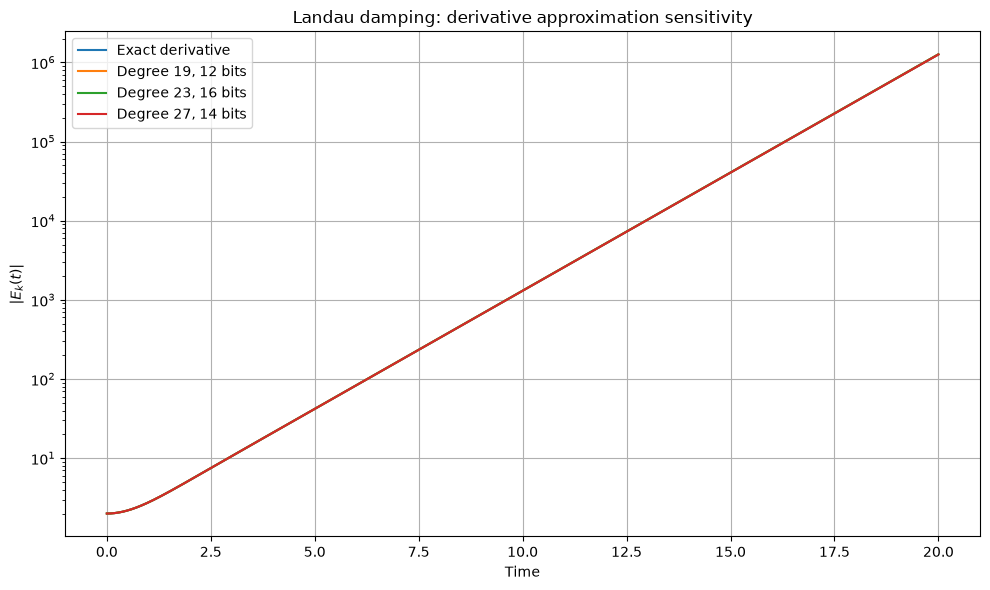

Damping-rate estimates:


,configuration,estimated_damping_rate,fit_R2,initial_field_amplitude,final_field_amplitude
0,Exact derivative,-0.687629,1.0,2.0,1.262943e+06
1,"Degree 19, 12 bits",-0.687730,1.0,2.0,1.264722e+06
2,"Degree 23, 16 bits",-0.687651,1.0,2.0,1.263448e+06
3,"Degree 27, 14 bits",-0.687377,1.0,2.0,1.256512e+06


Electric-field comparison against exact derivative:


,configuration,relative_field_history_L2_error,maximum_amplitude_difference_normalized
0,Exact derivative,0.000000,0.000000
1,"Degree 19, 12 bits",0.001337,0.001409
2,"Degree 23, 16 bits",0.000384,0.000400
3,"Degree 27, 14 bits",0.004912,0.005092


Results saved to: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from numpy.polynomial import Chebyshev
from scipy.linalg import solve

# --------------------------------------------------
# 1. Physical and numerical parameters
# --------------------------------------------------

Nv = 128
k = 0.5
dt = 0.001
t_final = 20.0

v = np.linspace(-6.0, 6.0, Nv)
dv = v[1] - v[0]

# Trapezoidal quadrature weights
w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
fp_exact = -v * f0

# Dense grid for constructing and validating polynomials
v_dense = np.linspace(-6.0, 6.0, 20001)

def maxwellian_derivative(x):
    return -x * np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)


# --------------------------------------------------
# 2. Construct the reference and approximations
# --------------------------------------------------

configurations = {
    "Exact derivative": None,
    "Degree 19, 12 bits": (19, 12),
    "Degree 23, 16 bits": (23, 16),
    "Degree 27, 14 bits": (27, 14),
}

derivatives = {}

for name, settings in configurations.items():

    if settings is None:
        derivatives[name] = fp_exact.copy()
        continue

    degree, bits = settings

    poly = Chebyshev.interpolate(
        maxwellian_derivative,
        deg=degree,
        domain=[-6.0, 6.0]
    )

    coeff = poly.coef.copy()

    # Enforce odd symmetry
    coeff[::2] = 0.0

    # Same fixed-point quantization as the previous experiment
    scale = 2**bits
    coeff_q = np.round(coeff * scale) / scale

    poly_q = Chebyshev(
        coeff_q,
        domain=poly.domain,
        window=poly.window
    )

    derivatives[name] = poly_q(v)


# --------------------------------------------------
# 3. Initial Fourier-mode perturbation
# --------------------------------------------------

# Consistent with the first-order perturbation of
# f(x,v,0) = f0(v) * [1 + alpha*cos(k*x)].
#
# The Fourier coefficient of the cosine perturbation
# is proportional to f0(v). Its overall scale does
# not affect the damping rate.

f_initial = f0.astype(complex)


# --------------------------------------------------
# 4. Implicit-Euler evolution
# --------------------------------------------------

n_steps = round(t_final / dt)
times = np.arange(n_steps + 1) * dt

results = {}
summary_rows = []

V = np.diag(v.astype(complex))
I = np.eye(Nv, dtype=complex)

for name, fp in derivatives.items():

    M = (
        -1j * k * V
        + np.outer(fp, w) / (1j * k)
    )

    A = I - dt * M

    f = f_initial.copy()
    electric_field = np.empty(n_steps + 1, dtype=complex)

    electric_field[0] = -np.dot(w, f) / (1j * k)

    # Factorization reuse is possible because A is constant.
    # For this first experiment, solve at each step.
    for n in range(n_steps):
        f = solve(A, f, assume_a="gen")
        electric_field[n + 1] = -np.dot(w, f) / (1j * k)

    results[name] = {
        "time": times,
        "E": electric_field,
    }

    # --------------------------------------------------
    # Estimate damping rate from log(|E|)
    # --------------------------------------------------

    amplitude = np.abs(electric_field)

    # Fit over an initial interval, avoiding t=0 and
    # values too close to numerical noise.
    fit_mask = (
        (times >= 2.0)
        & (times <= 12.0)
        & (amplitude > 1e-12)
    )

    fit_t = times[fit_mask]
    fit_y = np.log(amplitude[fit_mask])

    slope, intercept = np.polyfit(fit_t, fit_y, 1)

    fitted_y = slope * fit_t + intercept

    ss_res = np.sum((fit_y - fitted_y)**2)
    ss_tot = np.sum((fit_y - np.mean(fit_y))**2)

    r_squared = (
        1.0 - ss_res / ss_tot
        if ss_tot > 0 else np.nan
    )

    summary_rows.append({
        "configuration": name,
        "estimated_damping_rate": -slope,
        "fit_R2": r_squared,
        "initial_field_amplitude": amplitude[0],
        "final_field_amplitude": amplitude[-1],
    })


# --------------------------------------------------
# 5. Compare field histories
# --------------------------------------------------

plt.figure(figsize=(10, 6))

for name, result in results.items():
    plt.semilogy(
        result["time"],
        np.maximum(np.abs(result["E"]), 1e-16),
        label=name
    )

plt.xlabel("Time")
plt.ylabel(r"$|E_k(t)|$")
plt.title("Landau damping: derivative approximation sensitivity")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Relative field-history errors
# --------------------------------------------------

E_reference = results["Exact derivative"]["E"]
reference_norm = np.linalg.norm(E_reference)

error_rows = []

for name, result in results.items():

    E = result["E"]

    relative_error = (
        np.linalg.norm(E - E_reference)
        / reference_norm
    )

    max_relative_amplitude_error = (
        np.max(np.abs(np.abs(E) - np.abs(E_reference)))
        / max(np.max(np.abs(E_reference)), 1e-15)
    )

    error_rows.append({
        "configuration": name,
        "relative_field_history_L2_error": relative_error,
        "maximum_amplitude_difference_normalized":
            max_relative_amplitude_error,
    })


summary_df = pd.DataFrame(summary_rows)
error_df = pd.DataFrame(error_rows)

print("Damping-rate estimates:")
display(summary_df)

print("Electric-field comparison against exact derivative:")
display(error_df)


# --------------------------------------------------
# 7. Save results
# --------------------------------------------------

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

out_dir = project_root / "results" / "tables"
out_dir.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    out_dir / "derivative_approximation_damping_rates.csv",
    index=False
)

error_df.to_csv(
    out_dir / "derivative_approximation_field_errors.csv",
    index=False
)

print(f"Results saved to: {out_dir.resolve()}")

In [24]:
import numpy as np
import pandas as pd

# Use the same parameters as the failed experiment
Nv = 128
k = 0.5

v = np.linspace(-6.0, 6.0, Nv)
dv = v[1] - v[0]

w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
fp_exact = -v * f0

V = np.diag(v.astype(complex))

# Diagnose both possible signs of the rank-one coupling.
rows = []

for sign in [+1, -1]:

    M = (
        -1j * k * V
        + sign * np.outer(fp_exact, w) / (1j * k)
    )

    eigenvalues = np.linalg.eigvals(M)

    rows.append({
        "coupling_sign": sign,
        "max_real_eigenvalue": np.max(eigenvalues.real),
        "min_real_eigenvalue": np.min(eigenvalues.real),
        "max_abs_eigenvalue": np.max(np.abs(eigenvalues)),
        "unstable_eigenvalues_real_gt_1e-10":
            np.sum(eigenvalues.real > 1e-10),
    })

diagnostic_df = pd.DataFrame(rows)
display(diagnostic_df)

,coupling_sign,max_real_eigenvalue,min_real_eigenvalue,max_abs_eigenvalue,unstable_eigenvalues_real_gt_1e-10
0,1,6.872019e-01,-6.872019e-01,3.0,1
1,-1,2.376408e-15,-2.288662e-15,3.0,0


In [25]:
import numpy as np
import pandas as pd

Nv = 128
k = 0.5

v = np.linspace(-6.0, 6.0, Nv)
dv = v[1] - v[0]

w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
fp = -v * f0

V = np.diag(v.astype(complex))

M = (
    -1j * k * V
    + np.outer(fp, w) / (1j * k)
)

eigenvalues = np.linalg.eigvals(M)

# Sort by real part, largest first
idx = np.argsort(eigenvalues.real)[::-1]
eigenvalues = eigenvalues[idx]

eigen_df = pd.DataFrame({
    "eigenvalue_real": eigenvalues.real,
    "eigenvalue_imag": eigenvalues.imag,
    "eigenvalue_magnitude": np.abs(eigenvalues),
})

display(eigen_df.head(10))

print(
    "Number of eigenvalues with positive real part:",
    np.sum(eigenvalues.real > 1e-10)
)

print(
    "Largest real part:",
    np.max(eigenvalues.real)
)

,eigenvalue_real,eigenvalue_imag,eigenvalue_magnitude
0,6.872019e-01,-5.144333e-16,0.687202
1,4.054651e-15,2.338578e+00,2.338578
2,3.521828e-15,-2.669291e+00,2.669291
3,2.671720e-15,-2.574803e+00,2.574803
4,2.040622e-15,-2.622047e+00,2.622047
5,1.977464e-15,-2.291331e+00,2.291331
6,1.690513e-15,2.480314e+00,2.480314
7,1.602228e-15,-1.581695e+00,1.581695
8,1.553139e-15,1.865951e+00,1.865951
9,1.512030e-15,2.716535e+00,2.716535


Number of eigenvalues with positive real part: 1
Largest real part: 0.6872019203363121


Dominant eigenvalue: (0.6872019203363121-5.144333444308165e-16j)
Growth rate: 0.6872019203363121
Oscillation frequency: -5.144333444308165e-16
Fraction of mode energy in outer 10% of each boundary: 2.024829350296492e-11


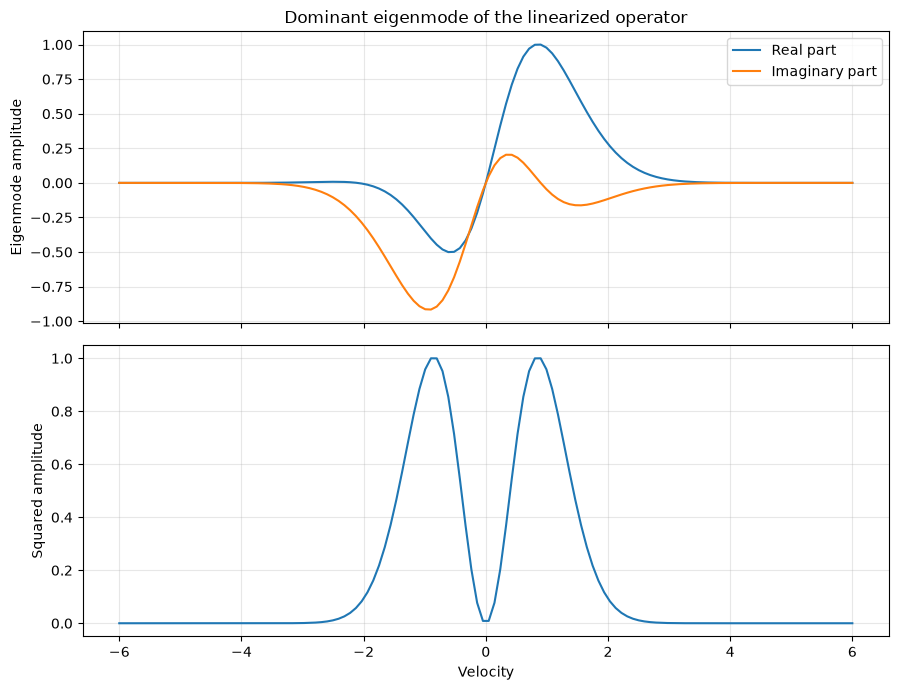

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Parameters
Nv = 128
k = 0.5

v = np.linspace(-6.0, 6.0, Nv)
dv = v[1] - v[0]

w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
fp = -v * f0

V = np.diag(v.astype(complex))

# Original operator
M = (
    -1j * k * V
    + np.outer(fp, w) / (1j * k)
)

# Eigenvalues and right eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(M)

idx = np.argmax(eigenvalues.real)
lambda_max = eigenvalues[idx]
mode = eigenvectors[:, idx]

# Normalize eigenmode
mode = mode / np.max(np.abs(mode))

print("Dominant eigenvalue:", lambda_max)
print("Growth rate:", lambda_max.real)
print("Oscillation frequency:", lambda_max.imag)

# Check where the eigenmode is concentrated
mode_energy = np.abs(mode)**2
total_energy = np.sum(mode_energy)

edge_count = max(1, Nv // 10)
edge_energy_fraction = (
    np.sum(mode_energy[:edge_count])
    + np.sum(mode_energy[-edge_count:])
) / total_energy

print("Fraction of mode energy in outer 10% of each boundary:",
      edge_energy_fraction)

# Plot the eigenmode
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

axes[0].plot(v, mode.real, label="Real part")
axes[0].plot(v, mode.imag, label="Imaginary part")
axes[0].set_ylabel("Eigenmode amplitude")
axes[0].set_title("Dominant eigenmode of the linearized operator")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(v, np.abs(mode)**2)
axes[1].set_xlabel("Velocity")
axes[1].set_ylabel("Squared amplitude")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()

# Save figures automatically
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
figure_dir = project_root / "results" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "dominant_eigenmode_landau_diagnostic.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    figure_dir / "dominant_eigenmode_landau_diagnostic.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

,Nv,max_real_eigenvalue,imaginary_part_of_dominant_eigenvalue,number_of_positive_real_eigenvalues
0,32,0.687202,4.772716e-16,1
1,64,0.687202,7.405090e-17,1
2,128,0.687202,1.789262e-16,1
3,256,0.687202,1.584381e-16,1
4,512,0.687202,-2.864614e-15,1


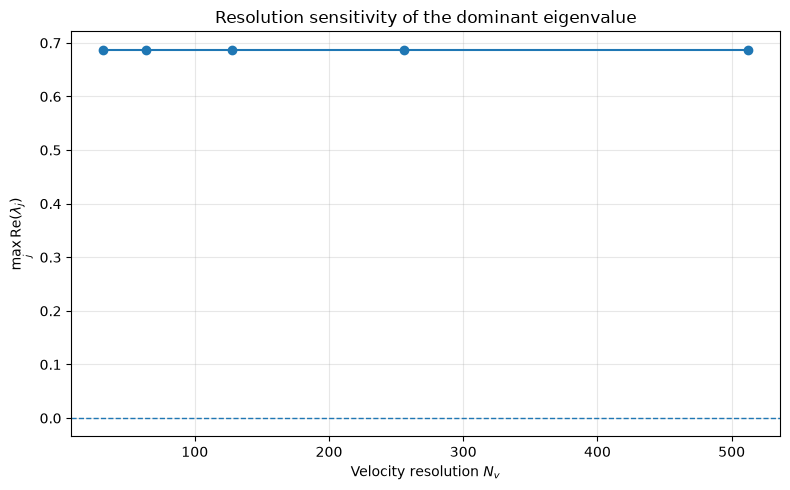

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

k = 0.5
Nv_values = [32, 64, 128, 256, 512]

rows = []

for Nv in Nv_values:
    v = np.linspace(-6.0, 6.0, Nv)
    dv = v[1] - v[0]

    w = np.full(Nv, dv)
    w[0] *= 0.5
    w[-1] *= 0.5

    fp = -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)

    # Matrix-free structure is not necessary at these sizes;
    # construct the dense matrix for this diagnostic.
    M = (
        -1j * k * np.diag(v)
        + np.outer(fp, w) / (1j * k)
    )

    eigvals = np.linalg.eigvals(M)

    idx = np.argmax(eigvals.real)
    lam = eigvals[idx]

    rows.append({
        "Nv": Nv,
        "max_real_eigenvalue": lam.real,
        "imaginary_part_of_dominant_eigenvalue": lam.imag,
        "number_of_positive_real_eigenvalues":
            int(np.sum(eigvals.real > 1e-10)),
    })

spectrum_df = pd.DataFrame(rows)
display(spectrum_df)

# Plot the dominant growth rate against resolution.
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    spectrum_df["Nv"],
    spectrum_df["max_real_eigenvalue"],
    marker="o",
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_xlabel(r"Velocity resolution $N_v$")
ax.set_ylabel(r"$\max_j \operatorname{Re}(\lambda_j)$")
ax.set_title("Resolution sensitivity of the dominant eigenvalue")
ax.grid(True, alpha=0.3)

fig.tight_layout()

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
figure_dir = project_root / "results" / "figures"
table_dir = project_root / "results" / "tables"

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "landau_dominant_eigenvalue_resolution.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    figure_dir / "landau_dominant_eigenvalue_resolution.pdf",
    bbox_inches="tight",
)

spectrum_df.to_csv(
    table_dir / "landau_dominant_eigenvalue_resolution.csv",
    index=False,
)

plt.show()
plt.close(fig)

,Nv,max_real_eigenvalue,imaginary_part_of_dominant_eigenvalue,number_of_positive_real_eigenvalues
0,32,2.308050e-15,-3.000000,0
1,64,3.592324e-15,2.809524,0
2,128,1.971529e-15,-2.811024,0
3,256,6.628319e-15,-2.952941,0
4,512,8.292633e-15,2.976517,0


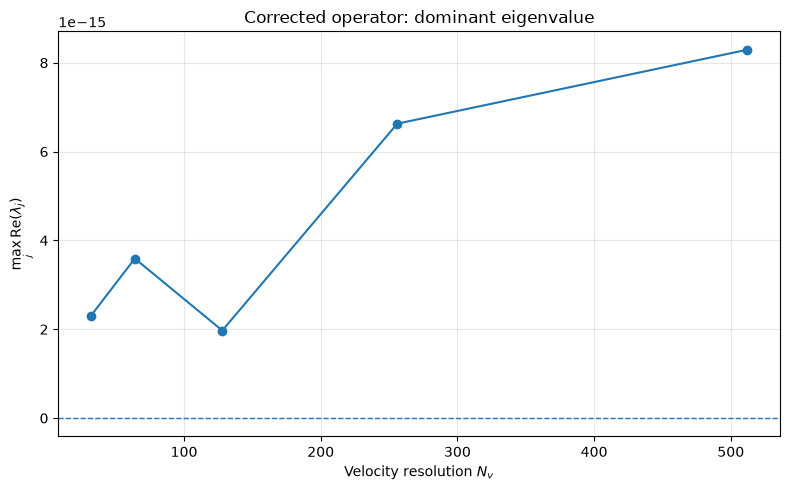

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

k = 0.5
Nv_values = [32, 64, 128, 256, 512]

rows = []

for Nv in Nv_values:
    v = np.linspace(-6.0, 6.0, Nv)
    dv = v[1] - v[0]

    w = np.full(Nv, dv)
    w[0] *= 0.5
    w[-1] *= 0.5

    fp = -v * np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)

    V = np.diag(v.astype(complex))

    # Corrected operator for the electron-force convention
    M = (
        -1j * k * V
        - np.outer(fp, w) / (1j * k)
    )

    eigvals = np.linalg.eigvals(M)

    idx = np.argmax(eigvals.real)
    lam = eigvals[idx]

    rows.append({
        "Nv": Nv,
        "max_real_eigenvalue": lam.real,
        "imaginary_part_of_dominant_eigenvalue": lam.imag,
        "number_of_positive_real_eigenvalues":
            int(np.sum(eigvals.real > 1e-10)),
    })

spectrum_df = pd.DataFrame(rows)
display(spectrum_df)

# Plot and save
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    spectrum_df["Nv"],
    spectrum_df["max_real_eigenvalue"],
    marker="o",
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xlabel(r"Velocity resolution $N_v$")
ax.set_ylabel(r"$\max_j \operatorname{Re}(\lambda_j)$")
ax.set_title("Corrected operator: dominant eigenvalue")
ax.grid(True, alpha=0.3)

fig.tight_layout()

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

figure_dir = project_root / "results" / "figures"
table_dir = project_root / "results" / "tables"

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "corrected_operator_eigenvalue_resolution.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    figure_dir / "corrected_operator_eigenvalue_resolution.pdf",
    bbox_inches="tight",
)

spectrum_df.to_csv(
    table_dir / "corrected_operator_eigenvalue_resolution.csv",
    index=False,
)

plt.show()
plt.close(fig)

Estimated growth/damping rate: -0.15682893
Equivalent damping rate gamma: 0.15682893
Fit R^2: 0.21104239
Initial |E|: 2.00000000e+00
Final |E|:   5.88541297e-02


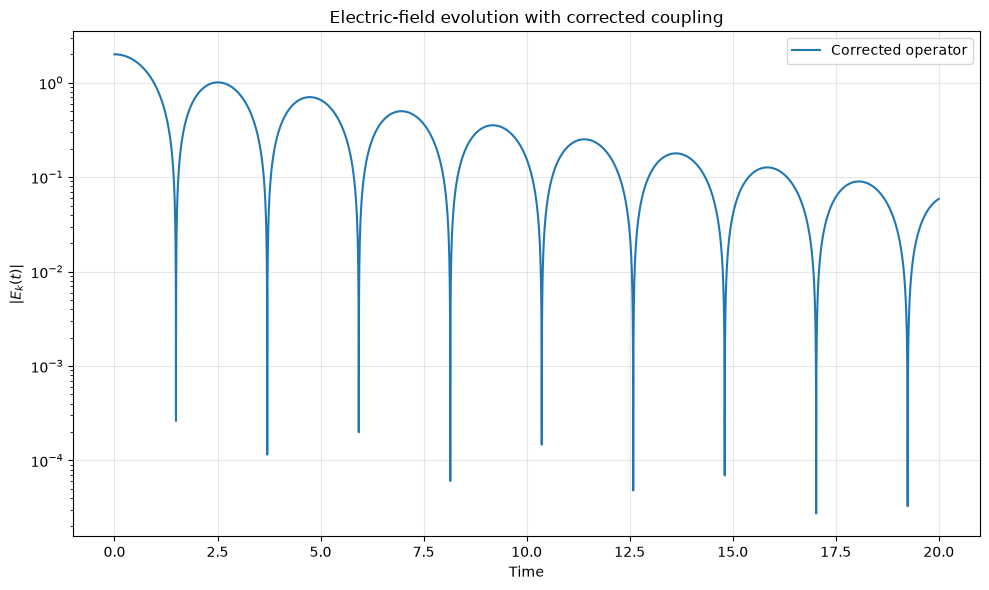

Figures saved in: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures
Tables saved in:  C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.linalg import lu_factor, lu_solve

# --------------------------------------------------
# 1. Parameters
# --------------------------------------------------

Nv = 128
k = 0.5
dt = 0.001
t_final = 20.0

v = np.linspace(-6.0, 6.0, Nv)
dv = v[1] - v[0]

w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
fp = -v * f0

V = np.diag(v.astype(complex))
I = np.eye(Nv, dtype=complex)

# --------------------------------------------------
# 2. Corrected linearized operator
# --------------------------------------------------

M = (
    -1j * k * V
    - np.outer(fp, w) / (1j * k)
)

# Implicit Euler: (I - dt*M) f[n+1] = f[n]
A = I - dt * M

# Factorize once, reuse at every timestep
lu, piv = lu_factor(A)

# --------------------------------------------------
# 3. Initial Fourier-mode perturbation
# --------------------------------------------------

f = f0.astype(complex).copy()

n_steps = round(t_final / dt)
times = np.arange(n_steps + 1) * dt

E = np.empty(n_steps + 1, dtype=complex)

def electric_field(fk):
    return -np.dot(w, fk) / (1j * k)

E[0] = electric_field(f)

for n in range(n_steps):
    f = lu_solve((lu, piv), f)
    E[n + 1] = electric_field(f)

amplitude = np.abs(E)

# --------------------------------------------------
# 4. Estimate an initial damping/growth rate
# --------------------------------------------------

fit_mask = (
    (times >= 2.0)
    & (times <= 12.0)
    & (amplitude > 1e-12)
)

fit_t = times[fit_mask]
fit_y = np.log(amplitude[fit_mask])

slope, intercept = np.polyfit(fit_t, fit_y, 1)

fit_line = np.exp(intercept + slope * fit_t)

ss_res = np.sum((fit_y - (intercept + slope * fit_t))**2)
ss_tot = np.sum((fit_y - np.mean(fit_y))**2)

r_squared = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

print(f"Estimated growth/damping rate: {slope:.8f}")
print(f"Equivalent damping rate gamma: {-slope:.8f}")
print(f"Fit R^2: {r_squared:.8f}")
print(f"Initial |E|: {amplitude[0]:.8e}")
print(f"Final |E|:   {amplitude[-1]:.8e}")

# --------------------------------------------------
# 5. Plot and save figures
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogy(
    times,
    np.maximum(amplitude, 1e-16),
    label="Corrected operator",
)

ax.set_xlabel("Time")
ax.set_ylabel(r"$|E_k(t)|$")
ax.set_title("Electric-field evolution with corrected coupling")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

figure_dir = project_root / "results" / "figures"
table_dir = project_root / "results" / "tables"

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "corrected_landau_field_evolution.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "corrected_landau_field_evolution.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# Save the complete time series
pd.DataFrame({
    "time": times,
    "E_real": E.real,
    "E_imag": E.imag,
    "E_amplitude": amplitude,
}).to_csv(
    table_dir / "corrected_landau_field_evolution.csv",
    index=False,
)

# Save the fit summary
pd.DataFrame([{
    "Nv": Nv,
    "k": k,
    "dt": dt,
    "t_final": t_final,
    "fit_start": 2.0,
    "fit_end": 12.0,
    "growth_rate": slope,
    "damping_rate": -slope,
    "fit_R2": r_squared,
}]).to_csv(
    table_dir / "corrected_landau_damping_fit.csv",
    index=False,
)

print(f"Figures saved in: {figure_dir.resolve()}")
print(f"Tables saved in:  {table_dir.resolve()}")

Number of peaks used: 7
Envelope damping rate: 0.15515599
Envelope fit R²: 0.99996063
Reference Landau damping rate: approximately 0.15336
Relative difference from reference: 1.171%


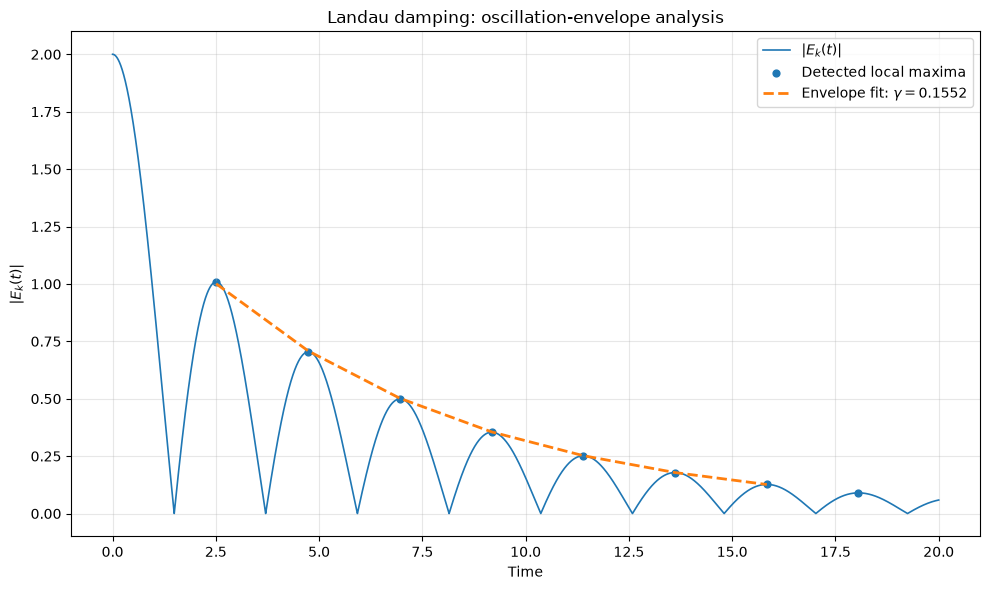

Figures saved to: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures
Tables saved to: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import find_peaks

# --------------------------------------------------
# 1. Load the existing simulation results
# --------------------------------------------------

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

table_dir = project_root / "results" / "tables"
figure_dir = project_root / "results" / "figures"

table_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

input_file = table_dir / "corrected_landau_field_evolution.csv"
df = pd.read_csv(input_file)

t = df["time"].to_numpy()
E_abs = df["E_amplitude"].to_numpy()

# --------------------------------------------------
# 2. Extract local maxima of |E|
# --------------------------------------------------

peak_indices, _ = find_peaks(E_abs)

peak_t = t[peak_indices]
peak_amp = E_abs[peak_indices]

# Restrict the fit to the interval used previously.
fit_mask = (
    (peak_t >= 2.0)
    & (peak_t <= 18.0)
    & (peak_amp > 0)
)

fit_t = peak_t[fit_mask]
fit_amp = peak_amp[fit_mask]

if len(fit_t) < 3:
    raise ValueError(
        "Too few peaks for a reliable envelope fit."
    )

# --------------------------------------------------
# 3. Fit an exponential to the peak amplitudes
# --------------------------------------------------

log_amp = np.log(fit_amp)

slope, intercept = np.polyfit(fit_t, log_amp, 1)

fitted_log_amp = intercept + slope * fit_t

ss_res = np.sum((log_amp - fitted_log_amp) ** 2)
ss_tot = np.sum((log_amp - np.mean(log_amp)) ** 2)

r_squared = (
    1 - ss_res / ss_tot
    if ss_tot > 0 else np.nan
)

gamma_envelope = -slope
C_envelope = np.exp(intercept)

print(f"Number of peaks used: {len(fit_t)}")
print(f"Envelope damping rate: {gamma_envelope:.8f}")
print(f"Envelope fit R²: {r_squared:.8f}")
print(f"Reference Landau damping rate: approximately 0.15336")
print(
    "Relative difference from reference: "
    f"{100 * abs(gamma_envelope - 0.15336) / 0.15336:.3f}%"
)

# --------------------------------------------------
# 4. Save the peak data and fit summary
# --------------------------------------------------

peaks_df = pd.DataFrame({
    "time": peak_t,
    "field_peak_amplitude": peak_amp,
})

peaks_df.to_csv(
    table_dir / "corrected_landau_envelope_peaks.csv",
    index=False,
)

summary_df = pd.DataFrame([{
    "fit_start": 2.0,
    "fit_end": 18.0,
    "number_of_peaks": len(fit_t),
    "envelope_damping_rate": gamma_envelope,
    "envelope_fit_R2": r_squared,
    "reference_damping_rate": 0.15336,
    "relative_difference_percent":
        100 * abs(gamma_envelope - 0.15336) / 0.15336,
}])

summary_df.to_csv(
    table_dir / "corrected_landau_envelope_fit.csv",
    index=False,
)

# --------------------------------------------------
# 5. Plot the signal and fitted envelope
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    t,
    E_abs,
    label=r"$|E_k(t)|$",
    linewidth=1.2,
)

ax.scatter(
    peak_t,
    peak_amp,
    label="Detected local maxima",
    s=24,
)

ax.plot(
    fit_t,
    C_envelope * np.exp(-gamma_envelope * fit_t),
    linestyle="--",
    label=fr"Envelope fit: $\gamma={gamma_envelope:.4f}$",
    linewidth=2,
)

ax.set_xlabel("Time")
ax.set_ylabel(r"$|E_k(t)|$")
ax.set_title("Landau damping: oscillation-envelope analysis")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    figure_dir / "corrected_landau_envelope_fit.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "corrected_landau_envelope_fit.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(f"Figures saved to: {figure_dir.resolve()}")
print(f"Tables saved to: {table_dir.resolve()}")

dt=0.0020 | gamma=0.15616063 | R²=0.99996319 | peaks=7
dt=0.0010 | gamma=0.15515599 | R²=0.99996063 | peaks=7
dt=0.0005 | gamma=0.15466485 | R²=0.99996069 | peaks=7


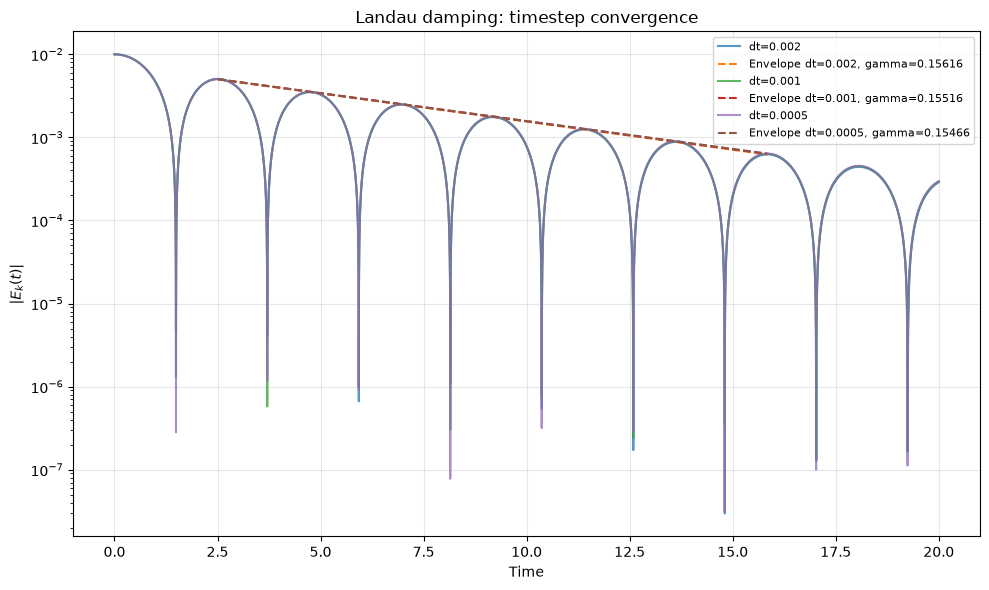


Saved figures and tables:
C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures
C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables


,dt,Nv,number_of_steps,number_of_peaks_used,initial_field_amplitude,final_field_amplitude,damping_rate,fit_R2
0,0.0020,128,10000,7,0.01,0.000288,0.156161,0.999963
1,0.0010,128,20000,7,0.01,0.000294,0.155156,0.999961
2,0.0005,128,40000,7,0.01,0.000298,0.154665,0.999961


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.linalg import lu_factor, lu_solve
from scipy.signal import find_peaks

# --------------------------------------------------
# 1. Parameters
# --------------------------------------------------

Nv = 128
k = 0.5
alpha = 0.01
t_final = 20.0

dt_values = [0.002, 0.001, 0.0005]

v = np.linspace(-6.0, 6.0, Nv)
dv = v[1] - v[0]

w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
fp = -v * f0

V = np.diag(v.astype(complex))
I = np.eye(Nv, dtype=complex)

# Corrected linearized operator
M = (
    -1j * k * V
    - np.outer(fp, w) / (1j * k)
)

# Correct Fourier coefficient of alpha*cos(k*x)
f_initial = (alpha / 2) * f0.astype(complex)

def electric_field(fk):
    return -np.dot(w, fk) / (1j * k)

# --------------------------------------------------
# 2. Run simulations and measure envelopes
# --------------------------------------------------

summary_rows = []
peak_datasets = []
curves = []

for dt in dt_values:

    n_steps = round(t_final / dt)
    times = np.arange(n_steps + 1) * dt

    A = I - dt * M
    lu, piv = lu_factor(A)

    f = f_initial.copy()

    E = np.empty(n_steps + 1, dtype=complex)
    E[0] = electric_field(f)

    for n in range(n_steps):
        f = lu_solve((lu, piv), f)
        E[n + 1] = electric_field(f)

    amplitude = np.abs(E)

    # Detect local maxima
    peak_indices, _ = find_peaks(amplitude)

    peak_t = times[peak_indices]
    peak_amp = amplitude[peak_indices]

    # Consistent fitting interval
    mask = (
        (peak_t >= 2.0)
        & (peak_t <= 18.0)
        & (peak_amp > 0)
    )

    fit_t = peak_t[mask]
    fit_amp = peak_amp[mask]

    log_amp = np.log(fit_amp)

    slope, intercept = np.polyfit(fit_t, log_amp, 1)

    fitted_log = intercept + slope * fit_t

    ss_res = np.sum((log_amp - fitted_log)**2)
    ss_tot = np.sum((log_amp - np.mean(log_amp))**2)

    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    gamma = -slope

    summary_rows.append({
        "dt": dt,
        "Nv": Nv,
        "number_of_steps": n_steps,
        "number_of_peaks_used": len(fit_t),
        "initial_field_amplitude": amplitude[0],
        "final_field_amplitude": amplitude[-1],
        "damping_rate": gamma,
        "fit_R2": r2,
    })

    peak_datasets.append(pd.DataFrame({
        "dt": dt,
        "time": fit_t,
        "peak_amplitude": fit_amp,
    }))

    curves.append({
        "dt": dt,
        "time": times,
        "amplitude": amplitude,
        "fit_time": fit_t,
        "fit_envelope": np.exp(intercept + slope * fit_t),
        "gamma": gamma,
    })

    print(
        f"dt={dt:.4f} | gamma={gamma:.8f} "
        f"| R²={r2:.8f} | peaks={len(fit_t)}"
    )

# --------------------------------------------------
# 3. Save numerical results
# --------------------------------------------------

summary_df = pd.DataFrame(summary_rows)
peaks_df = pd.concat(peak_datasets, ignore_index=True)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

figure_dir = project_root / "results" / "figures"
table_dir = project_root / "results" / "tables"

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    table_dir / "landau_timestep_convergence.csv",
    index=False,
)

peaks_df.to_csv(
    table_dir / "landau_timestep_convergence_peaks.csv",
    index=False,
)

# --------------------------------------------------
# 4. Plot all timestep results
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

for result in curves:

    dt = result["dt"]

    ax.semilogy(
        result["time"],
        result["amplitude"],
        label=f"dt={dt}",
        alpha=0.75,
    )

    ax.semilogy(
        result["fit_time"],
        result["fit_envelope"],
        linestyle="--",
        linewidth=1.5,
        label=f"Envelope dt={dt}, gamma={result['gamma']:.5f}",
    )

ax.set_xlabel("Time")
ax.set_ylabel(r"$|E_k(t)|$")
ax.set_title("Landau damping: timestep convergence")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()

fig.savefig(
    figure_dir / "landau_timestep_convergence.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "landau_timestep_convergence.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("\nSaved figures and tables:")
print(figure_dir.resolve())
print(table_dir.resolve())

display(summary_df)

Nv= 64 | gamma=0.15466485 | R²=0.99996069 | peaks=7
Nv=128 | gamma=0.15466485 | R²=0.99996069 | peaks=7
Nv=256 | gamma=0.15466485 | R²=0.99996069 | peaks=7


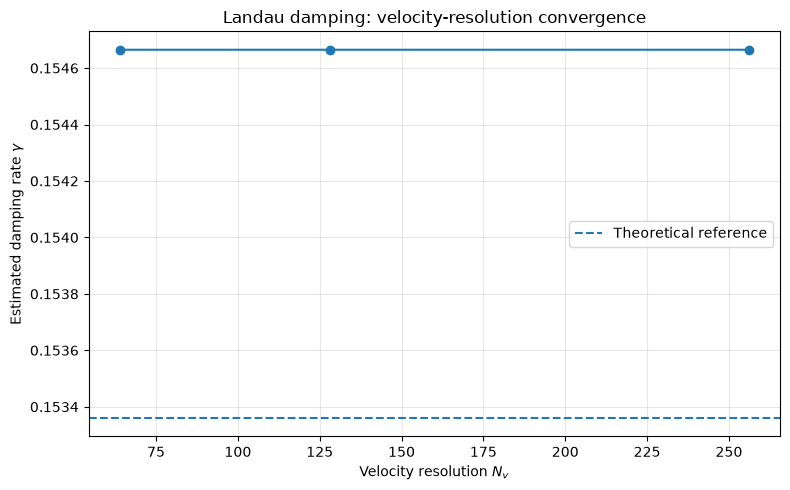

,Nv,dt,damping_rate,fit_R2,number_of_peaks,initial_field_amplitude,final_field_amplitude
0,64,0.0005,0.154665,0.999961,7,0.01,0.000298
1,128,0.0005,0.154665,0.999961,7,0.01,0.000298
2,256,0.0005,0.154665,0.999961,7,0.01,0.000298


Saved figures: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures
Saved tables: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import find_peaks

# --------------------------------------------------
# 1. Parameters
# --------------------------------------------------

Nv_values = [64, 128, 256]

k = 0.5
alpha = 0.01
dt = 0.0005
t_final = 20.0

results = []

# --------------------------------------------------
# 2. Run velocity-resolution experiments
# --------------------------------------------------

for Nv in Nv_values:

    v = np.linspace(-6.0, 6.0, Nv)
    dv = v[1] - v[0]

    w = np.full(Nv, dv)
    w[0] *= 0.5
    w[-1] *= 0.5

    f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    fp = -v * f0

    # Corrected operator:
    # M = -ikV - fp*w^T/(ik)

    # A = I - dt*M = D + u*w^T
    D = 1.0 + 1j * dt * k * v
    u = (dt / (1j * k)) * fp

    # Precompute Sherman-Morrison quantities
    D_inv = 1.0 / D
    Dinv_u = D_inv * u

    denominator = 1.0 + np.dot(w, Dinv_u)

    if abs(denominator) < 1e-12:
        raise RuntimeError("Sherman-Morrison denominator is too small.")

    # Initial positive Fourier coefficient
    f = (alpha / 2) * f0.astype(complex)

    n_steps = round(t_final / dt)
    times = np.arange(n_steps + 1) * dt

    E = np.empty(n_steps + 1, dtype=complex)

    E[0] = -np.dot(w, f) / (1j * k)

    # --------------------------------------------------
    # 3. Time evolution using Sherman-Morrison
    # --------------------------------------------------

    for n in range(n_steps):

        Dinv_f = D_inv * f

        correction = np.dot(w, Dinv_f) / denominator

        f = Dinv_f - Dinv_u * correction

        E[n + 1] = -np.dot(w, f) / (1j * k)

    amplitude = np.abs(E)

    # --------------------------------------------------
    # 4. Extract and fit envelope
    # --------------------------------------------------

    peak_indices, _ = find_peaks(amplitude)

    peak_t = times[peak_indices]
    peak_amp = amplitude[peak_indices]

    mask = (
        (peak_t >= 2.0)
        & (peak_t <= 18.0)
        & (peak_amp > 0)
    )

    fit_t = peak_t[mask]
    fit_amp = peak_amp[mask]

    slope, intercept = np.polyfit(
        fit_t,
        np.log(fit_amp),
        1
    )

    fitted = intercept + slope * fit_t

    ss_res = np.sum((np.log(fit_amp) - fitted)**2)
    ss_tot = np.sum((np.log(fit_amp) - np.mean(np.log(fit_amp)))**2)

    r2 = 1 - ss_res / ss_tot

    gamma = -slope

    results.append({
        "Nv": Nv,
        "dt": dt,
        "damping_rate": gamma,
        "fit_R2": r2,
        "number_of_peaks": len(fit_t),
        "initial_field_amplitude": amplitude[0],
        "final_field_amplitude": amplitude[-1],
    })

    print(
        f"Nv={Nv:3d} | gamma={gamma:.8f} "
        f"| R²={r2:.8f} | peaks={len(fit_t)}"
    )

# --------------------------------------------------
# 5. Save numerical results
# --------------------------------------------------

results_df = pd.DataFrame(results)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

figure_dir = project_root / "results" / "figures"
table_dir = project_root / "results" / "tables"

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    table_dir / "landau_velocity_resolution_convergence.csv",
    index=False,
)

# --------------------------------------------------
# 6. Plot and save
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    results_df["Nv"],
    results_df["damping_rate"],
    marker="o",
)

ax.axhline(
    0.15336,
    linestyle="--",
    label="Theoretical reference",
)

ax.set_xlabel(r"Velocity resolution $N_v$")
ax.set_ylabel(r"Estimated damping rate $\gamma$")
ax.set_title("Landau damping: velocity-resolution convergence")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    figure_dir / "landau_velocity_resolution_convergence.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "landau_velocity_resolution_convergence.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

display(results_df)

print("Saved figures:", figure_dir.resolve())
print("Saved tables:", table_dir.resolve())

Vmax= 4.0 | Nv=171 | dv=0.04706 | gamma=0.15450826 | R²=0.99994403
Vmax= 6.0 | Nv=257 | dv=0.04688 | gamma=0.15466485 | R²=0.99996069
Vmax= 8.0 | Nv=341 | dv=0.04706 | gamma=0.15466485 | R²=0.99996069
Vmax=10.0 | Nv=427 | dv=0.04695 | gamma=0.15466485 | R²=0.99996069


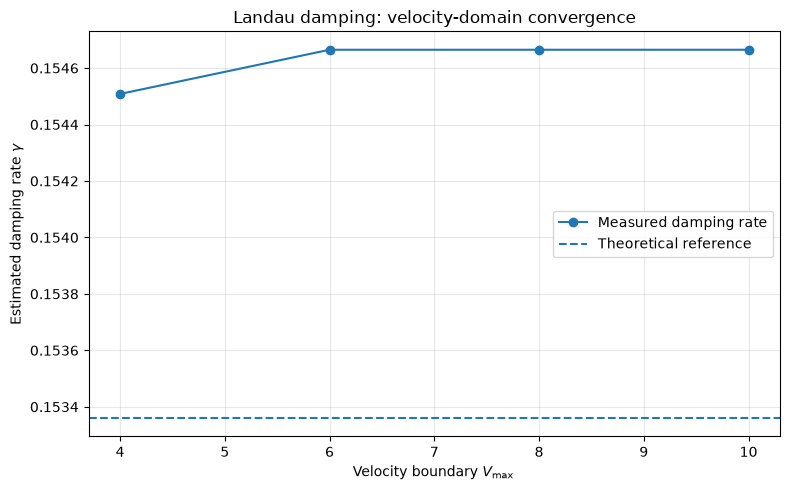

,Vmax,Nv,dv,damping_rate,fit_R2,number_of_peaks
0,4.0,171,0.047059,0.154508,0.999944,7
1,6.0,257,0.046875,0.154665,0.999961,7
2,8.0,341,0.047059,0.154665,0.999961,7
3,10.0,427,0.046948,0.154665,0.999961,7


Figures: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures
Tables: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import find_peaks

# --------------------------------------------------
# 1. Parameters
# --------------------------------------------------

Vmax_values = [4.0, 6.0, 8.0, 10.0]

target_dv = 0.047
k = 0.5
alpha = 0.01
dt = 0.0005
t_final = 20.0

results = []

# --------------------------------------------------
# 2. Domain convergence experiments
# --------------------------------------------------

for Vmax in Vmax_values:

    Nv = 2 * round(Vmax / target_dv) + 1

    v = np.linspace(-Vmax, Vmax, Nv)
    dv = v[1] - v[0]

    w = np.full(Nv, dv)
    w[0] *= 0.5
    w[-1] *= 0.5

    f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
    fp = -v * f0

    # A = D + u*w^T
    D = 1.0 + 1j * dt * k * v
    u = (dt / (1j * k)) * fp

    D_inv = 1.0 / D
    Dinv_u = D_inv * u

    denominator = 1.0 + np.dot(w, Dinv_u)

    f = (alpha / 2) * f0.astype(complex)

    n_steps = round(t_final / dt)
    times = np.arange(n_steps + 1) * dt

    E = np.empty(n_steps + 1, dtype=complex)
    E[0] = -np.dot(w, f) / (1j * k)

    # Sherman-Morrison time evolution
    for n in range(n_steps):

        Dinv_f = D_inv * f

        correction = np.dot(w, Dinv_f) / denominator

        f = Dinv_f - Dinv_u * correction

        E[n + 1] = -np.dot(w, f) / (1j * k)

    amplitude = np.abs(E)

    # Extract envelope peaks
    peak_indices, _ = find_peaks(amplitude)

    peak_t = times[peak_indices]
    peak_amp = amplitude[peak_indices]

    mask = (
        (peak_t >= 2.0)
        & (peak_t <= 18.0)
        & (peak_amp > 0)
    )

    fit_t = peak_t[mask]
    fit_amp = peak_amp[mask]

    slope, intercept = np.polyfit(
        fit_t,
        np.log(fit_amp),
        1
    )

    fitted = intercept + slope * fit_t

    log_amp = np.log(fit_amp)

    ss_res = np.sum((log_amp - fitted)**2)
    ss_tot = np.sum((log_amp - np.mean(log_amp))**2)

    r2 = 1 - ss_res / ss_tot

    gamma = -slope

    results.append({
        "Vmax": Vmax,
        "Nv": Nv,
        "dv": dv,
        "damping_rate": gamma,
        "fit_R2": r2,
        "number_of_peaks": len(fit_t),
    })

    print(
        f"Vmax={Vmax:4.1f} | Nv={Nv:3d} "
        f"| dv={dv:.5f} | gamma={gamma:.8f} "
        f"| R²={r2:.8f}"
    )

# --------------------------------------------------
# 3. Save results
# --------------------------------------------------

results_df = pd.DataFrame(results)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

figure_dir = project_root / "results" / "figures"
table_dir = project_root / "results" / "tables"

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    table_dir / "landau_velocity_domain_convergence.csv",
    index=False,
)

# --------------------------------------------------
# 4. Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    results_df["Vmax"],
    results_df["damping_rate"],
    marker="o",
    label="Measured damping rate",
)

ax.axhline(
    0.15336,
    linestyle="--",
    label="Theoretical reference",
)

ax.set_xlabel(r"Velocity boundary $V_{\max}$")
ax.set_ylabel(r"Estimated damping rate $\gamma$")
ax.set_title("Landau damping: velocity-domain convergence")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    figure_dir / "landau_velocity_domain_convergence.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "landau_velocity_domain_convergence.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

display(results_df)

print("Figures:", figure_dir.resolve())
print("Tables:", table_dir.resolve())

Fit window [2.0, 18.0] | gamma=0.15466485 | R²=0.99996069 | peaks=7
Fit window [4.0, 18.0] | gamma=0.15391401 | R²=0.99999976 | peaks=6
Fit window [6.0, 18.0] | gamma=0.15384874 | R²=1.00000000 | peaks=5
Fit window [8.0, 18.0] | gamma=0.15385132 | R²=1.00000000 | peaks=4


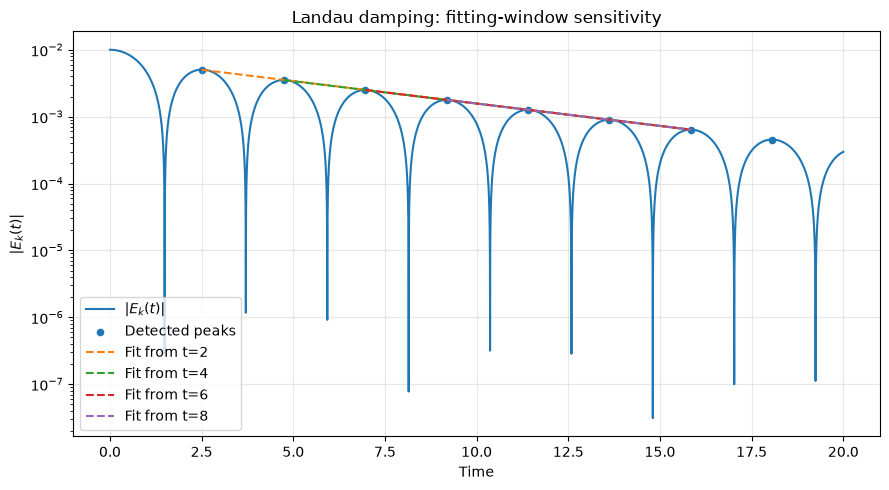

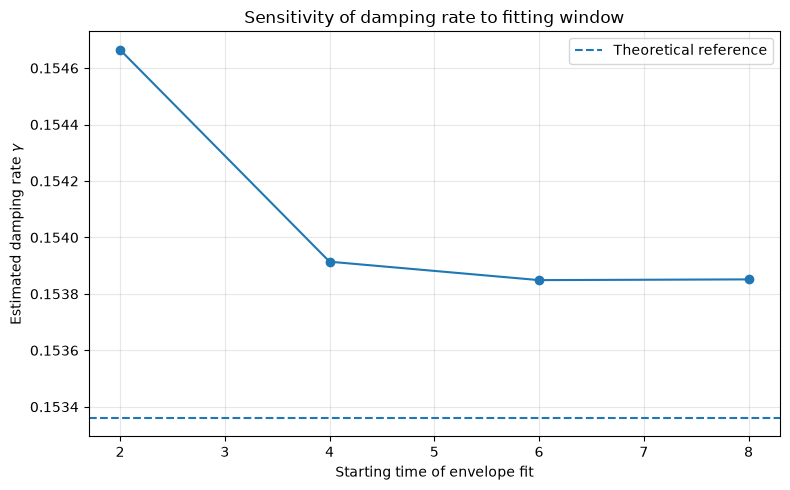

,fit_start,fit_end,number_of_peaks,damping_rate,fit_R2
0,2.0,18.0,7,0.154665,0.999961
1,4.0,18.0,6,0.153914,1.000000
2,6.0,18.0,5,0.153849,1.000000
3,8.0,18.0,4,0.153851,1.000000


Figures saved in: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures
Tables saved in: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import find_peaks

# --------------------------------------------------
# 1. Fixed physical parameters
# --------------------------------------------------

Vmax = 6.0
Nv = 257

k = 0.5
alpha = 0.01
dt = 0.0005
t_final = 20.0

fit_start_values = [2.0, 4.0, 6.0, 8.0]
fit_end = 18.0

# --------------------------------------------------
# 2. Construct velocity grid and operator
# --------------------------------------------------

v = np.linspace(-Vmax, Vmax, Nv)
dv = v[1] - v[0]

w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
fp = -v * f0

D = 1.0 + 1j * dt * k * v
u = (dt / (1j * k)) * fp

D_inv = 1.0 / D
Dinv_u = D_inv * u

denominator = 1.0 + np.dot(w, Dinv_u)

# --------------------------------------------------
# 3. Time evolution
# --------------------------------------------------

f = (alpha / 2) * f0.astype(complex)

n_steps = round(t_final / dt)
times = np.arange(n_steps + 1) * dt

E = np.empty(n_steps + 1, dtype=complex)
E[0] = -np.dot(w, f) / (1j * k)

for n in range(n_steps):

    Dinv_f = D_inv * f
    correction = np.dot(w, Dinv_f) / denominator

    f = Dinv_f - Dinv_u * correction

    E[n + 1] = -np.dot(w, f) / (1j * k)

amplitude = np.abs(E)

# --------------------------------------------------
# 4. Detect envelope peaks
# --------------------------------------------------

peak_indices, _ = find_peaks(amplitude)

peak_t = times[peak_indices]
peak_amp = amplitude[peak_indices]

rows = []
fit_curves = {}

for start in fit_start_values:

    mask = (
        (peak_t >= start)
        & (peak_t <= fit_end)
        & (peak_amp > 0)
    )

    fit_t = peak_t[mask]
    fit_amp = peak_amp[mask]

    if len(fit_t) < 3:
        print(f"Skipping start={start}: insufficient peaks.")
        continue

    log_amp = np.log(fit_amp)

    slope, intercept = np.polyfit(fit_t, log_amp, 1)

    fitted = intercept + slope * fit_t

    ss_res = np.sum((log_amp - fitted)**2)
    ss_tot = np.sum((log_amp - np.mean(log_amp))**2)

    r2 = 1 - ss_res / ss_tot

    gamma = -slope

    rows.append({
        "fit_start": start,
        "fit_end": fit_end,
        "number_of_peaks": len(fit_t),
        "damping_rate": gamma,
        "fit_R2": r2,
    })

    fit_curves[start] = (fit_t, fitted)

    print(
        f"Fit window [{start:.1f}, {fit_end:.1f}] "
        f"| gamma={gamma:.8f} "
        f"| R²={r2:.8f} "
        f"| peaks={len(fit_t)}"
    )

# --------------------------------------------------
# 5. Save numerical data
# --------------------------------------------------

results_df = pd.DataFrame(rows)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

figure_dir = project_root / "results" / "figures"
table_dir = project_root / "results" / "tables"

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    table_dir / "landau_fit_window_sensitivity.csv",
    index=False,
)

# Preserve the complete time series for later analysis
pd.DataFrame({
    "time": times,
    "electric_field_magnitude": amplitude,
}).to_csv(
    table_dir / "landau_fit_window_timeseries.csv",
    index=False,
)

# --------------------------------------------------
# 6. Plot and save envelope fits
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    times,
    amplitude,
    label=r"$|E_k(t)|$",
)

ax.scatter(
    peak_t,
    peak_amp,
    s=20,
    label="Detected peaks",
)

for start, (fit_t, fitted) in fit_curves.items():

    ax.plot(
        fit_t,
        np.exp(fitted),
        linestyle="--",
        label=f"Fit from t={start:g}",
    )

ax.set_yscale("log")
ax.set_xlabel("Time")
ax.set_ylabel(r"$|E_k(t)|$")
ax.set_title("Landau damping: fitting-window sensitivity")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    figure_dir / "landau_fit_window_sensitivity.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "landau_fit_window_sensitivity.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# --------------------------------------------------
# 7. Plot damping rate against fit start
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    results_df["fit_start"],
    results_df["damping_rate"],
    marker="o",
)

ax.axhline(
    0.15336,
    linestyle="--",
    label="Theoretical reference",
)

ax.set_xlabel("Starting time of envelope fit")
ax.set_ylabel(r"Estimated damping rate $\gamma$")
ax.set_title("Sensitivity of damping rate to fitting window")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    figure_dir / "landau_fit_window_rate.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "landau_fit_window_rate.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

display(results_df)

print("Figures saved in:", figure_dir.resolve())
print("Tables saved in:", table_dir.resolve())

dt=0.0020 | window=4-18 | gamma=0.15542660 | R²=0.99999981
dt=0.0020 | window=6-18 | gamma=0.15536942 | R²=0.99999998
dt=0.0010 | window=4-18 | gamma=0.15440235 | R²=0.99999974
dt=0.0010 | window=6-18 | gamma=0.15433480 | R²=0.99999999
dt=0.0005 | window=4-18 | gamma=0.15391401 | R²=0.99999976
dt=0.0005 | window=6-18 | gamma=0.15384874 | R²=1.00000000


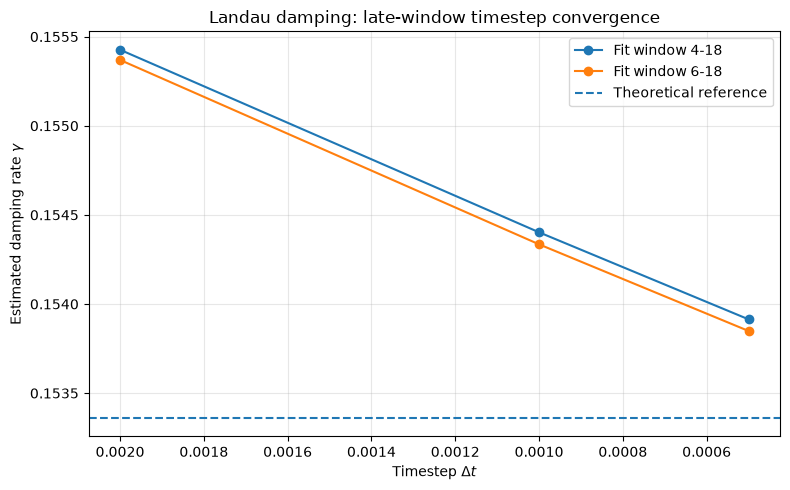

,dt,fit_start,fit_end,number_of_peaks,damping_rate,fit_R2
0,0.0020,4.0,18.0,6,0.155427,1.0
1,0.0020,6.0,18.0,5,0.155369,1.0
2,0.0010,4.0,18.0,6,0.154402,1.0
3,0.0010,6.0,18.0,5,0.154335,1.0
4,0.0005,4.0,18.0,6,0.153914,1.0
5,0.0005,6.0,18.0,5,0.153849,1.0


Figures saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures
Tables saved: C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\tables


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import find_peaks

# --------------------------------------------------
# 1. Fixed physical parameters
# --------------------------------------------------

Vmax = 6.0
Nv = 257

k = 0.5
alpha = 0.01
t_final = 20.0

dt_values = [0.002, 0.001, 0.0005]
fit_windows = [(4.0, 18.0), (6.0, 18.0)]

v = np.linspace(-Vmax, Vmax, Nv)
dv = v[1] - v[0]

w = np.full(Nv, dv)
w[0] *= 0.5
w[-1] *= 0.5

f0 = np.exp(-v**2 / 2) / np.sqrt(2 * np.pi)
fp = -v * f0

rows = []

# --------------------------------------------------
# 2. Timestep convergence
# --------------------------------------------------

for dt in dt_values:

    D = 1.0 + 1j * dt * k * v
    u = (dt / (1j * k)) * fp

    D_inv = 1.0 / D
    Dinv_u = D_inv * u

    denominator = 1.0 + np.dot(w, Dinv_u)

    f = (alpha / 2) * f0.astype(complex)

    n_steps = round(t_final / dt)
    times = np.arange(n_steps + 1) * dt

    E = np.empty(n_steps + 1, dtype=complex)
    E[0] = -np.dot(w, f) / (1j * k)

    # Sherman-Morrison time integration
    for n in range(n_steps):

        Dinv_f = D_inv * f
        correction = np.dot(w, Dinv_f) / denominator

        f = Dinv_f - Dinv_u * correction

        E[n + 1] = -np.dot(w, f) / (1j * k)

    amplitude = np.abs(E)

    peak_indices, _ = find_peaks(amplitude)

    peak_t = times[peak_indices]
    peak_amp = amplitude[peak_indices]

    # --------------------------------------------------
    # 3. Fit using both windows
    # --------------------------------------------------

    for start, end in fit_windows:

        mask = (
            (peak_t >= start)
            & (peak_t <= end)
            & (peak_amp > 0)
        )

        fit_t = peak_t[mask]
        fit_amp = peak_amp[mask]

        if len(fit_t) < 3:
            continue

        log_amp = np.log(fit_amp)

        slope, intercept = np.polyfit(
            fit_t, log_amp, 1
        )

        fitted = intercept + slope * fit_t

        ss_res = np.sum((log_amp - fitted)**2)
        ss_tot = np.sum((log_amp - np.mean(log_amp))**2)

        r2 = 1 - ss_res / ss_tot

        rows.append({
            "dt": dt,
            "fit_start": start,
            "fit_end": end,
            "number_of_peaks": len(fit_t),
            "damping_rate": -slope,
            "fit_R2": r2,
        })

        print(
            f"dt={dt:.4f} | window={start:.0f}-{end:.0f} "
            f"| gamma={-slope:.8f} "
            f"| R²={r2:.8f}"
        )

# --------------------------------------------------
# 4. Save results
# --------------------------------------------------

results_df = pd.DataFrame(rows)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

figure_dir = project_root / "results" / "figures"
table_dir = project_root / "results" / "tables"

figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    table_dir / "landau_timestep_convergence_late_windows.csv",
    index=False,
)

# --------------------------------------------------
# 5. Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

for start, end in fit_windows:

    subset = results_df[
        results_df["fit_start"] == start
    ].sort_values("dt")

    ax.plot(
        subset["dt"],
        subset["damping_rate"],
        marker="o",
        label=f"Fit window {start:.0f}-{end:.0f}",
    )

ax.axhline(
    0.15336,
    linestyle="--",
    label="Theoretical reference",
)

ax.set_xlabel(r"Timestep $\Delta t$")
ax.set_ylabel(r"Estimated damping rate $\gamma$")
ax.set_title("Landau damping: late-window timestep convergence")

ax.invert_xaxis()
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    figure_dir / "landau_late_window_timestep_convergence.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    figure_dir / "landau_late_window_timestep_convergence.pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

display(results_df)

print("Figures saved:", figure_dir.resolve())
print("Tables saved:", table_dir.resolve())